# TP2 - Etapa 2: entrenamiento, evaluación y comparación de modelos

Notebook de entrenamiento y estudio de resultados: evaluación de la búsqueda por similitud
(Etapa 1, NDCG@10), fine-tuning de ResNet (Modelo A), CNN propia (Modelo B) y comparación entre
modelos (ver `ENUNCIADO.md`, secciones 4.3 y 5). **Ambos modelos son obligatorios.**

Requisitos previos (en el fork):
- Funciones de la Etapa 1 implementadas en `src/lib/services/similarity_service.py`.
- `train_classifier`, `evaluate_classifier` y `extract_custom_embedding` implementadas en
  `src/lib/services/classifier_service.py` (esta notebook solo las orquesta).
- Splits y conjunto independiente generados en `1-pre-processing.ipynb`.

**Notebook en Google Colab:** no se usa. La notebook se entrega ejecutada en el repositorio
(opción 1 de la sección 8.2 del enunciado); se corrió en local con GPU (GTX 1650, 4 GB).

## Equipo
- Alumno 1 : Facundo Quinteros — Q-0493/6 — @FacuQuinteros03
- Alumno 2 : Roberto Lasarte — L-3370/7 — @RoberLasarte332

## 1. Clonar el repositorio

Solo si se trabaja en Colab (en local la notebook se corre desde la raíz del repositorio).

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/FacuQuinteros03/tuia-dog-recognition-app.git"
    !git clone -b feature/tp2-razas-perros $REPO_URL proyecto
    %cd proyecto
print("Colab:", IN_COLAB)

Colab: False


## 2. Instalar dependencias

En local se usa el entorno de `requirements.txt`. En Colab solo se instala lo que falta.

In [2]:
if IN_COLAB:
    !pip install -q pydantic-settings python-dotenv kagglehub albumentations onnxruntime

## 3. Configuración del entorno

Se desactiva pgvector y se usa la base vectorial JSON: para evaluar no hace falta la base de datos
(sección 5). La configuración se define por variables de entorno **antes** de importar `lib`.
Los pesos preentrenados se cachean en `models/torch` (`TORCH_HOME`, igual que en la app) y los
embeddings calculados en `output/nb2/`, que está fuera del control de versiones.

In [3]:
import os
import random
import time
import warnings
from pathlib import Path

ROOT = Path.cwd()
os.environ["USE_PGVECTOR"] = "false"
os.environ.setdefault("TORCH_HOME", str(ROOT / "models" / "torch"))
os.environ.setdefault("YOLO_MODEL", str(ROOT / "models" / "yolov8n.pt"))   # igual que en los .env de la app
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from lib.config import settings
from lib.preprocessing import bgr_to_rgb, read_bgr

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATASET = ROOT / "data" / "dataset"
CACHE = ROOT / "output" / "nb2"
CACHE.mkdir(parents=True, exist_ok=True)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

pd.set_option("display.max_rows", 80)
pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 90
# Figuras en JPEG: las grillas de fotos en PNG hacen que la notebook pese demasiado para GitHub.
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("jpeg", pil_kwargs={"quality": 85})
print("dataset_path:", settings.dataset_path)
print("GPU disponible:", torch.cuda.is_available(), torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

/root/venvs/tp2/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


dataset_path: data/dataset/clean
GPU disponible: True NVIDIA GeForce GTX 1650


## 4. Dataset y splits

Se usan los splits de `1-pre-processing.ipynb` (`data/splits.csv`, con las imágenes ya copiadas a
`data/dataset/clean/<split>/<raza>/`) y el conjunto independiente (`data/independent_sources.csv`,
imágenes en `data/dataset/independent/<raza>/` y `data/dataset/independent_scenes/<escena>/`).
Si el dataset no está, se descarga y hay que ejecutar primero la notebook 1.

In [4]:
if not settings.dataset_path.is_dir():
    !python scripts/download_dataset.py
    raise SystemExit("Ejecutar 1-pre-processing.ipynb para generar data/dataset/clean y data/splits.csv")

splits = pd.read_csv(ROOT / "data" / "splits.csv")
splits["abs_path"] = [str(settings.dataset_path / p) for p in splits.path]
SETS = {s: splits[splits.split == s].reset_index(drop=True) for s in ("train", "valid", "test")}

indep_all = pd.read_csv(ROOT / "data" / "independent_sources.csv")
indep_all["abs_path"] = [
    str((DATASET / "independent" if g == "breed" else DATASET / "independent_scenes") / l / Path(f).name)
    for g, l, f in zip(indep_all.group, indep_all.label, indep_all.file)
]
SETS["independent"] = indep_all
assert all(Path(p).is_file() for df in SETS.values() for p in df.abs_path), "faltan imágenes"

summary = pd.DataFrame({
    "imágenes": {k: len(v) for k, v in SETS.items()},
    "razas": {k: (v.breed if "breed" in v else v.label[v.group == "breed"]).nunique() for k, v in SETS.items()},
})
display(summary)
print(indep_all.group.value_counts().to_string())

,imágenes,razas
train,5994,70
valid,1285,70
test,1285,70
independent,133,24


group
breed        100
no_dog        20
multi_dog     13


## 5. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

**Protocolo** (enunciado 4.3):

- **Galería:** las imágenes de `train` (5994). **Consultas:** `test` y las 100 imágenes de razas
  del conjunto independiente, que nunca se indexan. `valid` se usa solo para calibrar el umbral.
- **Extractor:** `SimilarityService.extract_embedding`, la misma función que usa la app: ResNet18
  preentrenado en ImageNet sin la capa `fc` (embedding de 512 = `EMBEDDING_DIM`), con el
  preprocesamiento compartido de `lib/preprocessing.py` y normalización L2.
- **Por qué ResNet18:** su embedding coincide con `EMBEDDING_DIM=512` y con el del ResNet18
  fine-tuned del Modelo A, así la misma tabla de pgvector sirve para los dos y la comparación
  baseline vs. fine-tuned (sección 9) es sobre la misma arquitectura.
- **Búsqueda:** como sugiere el enunciado, la galería se guarda en una matriz de `numpy` y se busca
  con un producto matricial. En 5.2 se verifica que da los mismos vecinos que
  `search_similar_images` del servicio.
- **Raza predicha:** `predict_breed_from_neighbors` del servicio (voto ponderado por similitud).
- **Métricas:** NDCG@10 con relevancia binaria e `n_relevant` = imágenes de la raza en la galería
  (`ndcg_at_k` de `src/lib/evaluation/metrics.py`), precision@10 y accuracy de la raza predicha.

### 5.1 Embeddings de la galería y de las consultas

Se calculan una vez y se guardan en `output/nb2/` (si el archivo existe y tiene la misma cantidad
de filas, se reutiliza).

In [5]:
from lib.bootstrap import build_similarity, build_store
from lib.evaluation.metrics import ndcg_at_k
from lib.schemas import Neighbor

similarity = build_similarity(settings, build_store(settings))


def embed_set(name, paths, extractor, tag="baseline"):
    f = CACHE / f"emb_{tag}_{name}.npy"
    if f.exists():
        E = np.load(f)
        if len(E) == len(paths):
            return E
    t0 = time.time()
    E = np.asarray([extractor(read_bgr(p)) for p in paths], dtype=np.float32)
    print(f"{tag}/{name}: {len(E)} embeddings en {time.time() - t0:.0f} s")
    np.save(f, E)
    return E


EMB = {k: embed_set(k, v.abs_path.tolist(), similarity.extract_embedding) for k, v in SETS.items()}

# Tiempo de extracción por imagen (incluye lectura y preprocesamiento)
sample = SETS["test"].abs_path.tolist()[:50]
t0 = time.time()
for p in sample:
    similarity.extract_embedding(read_bgr(p))
ms = (time.time() - t0) / len(sample) * 1000
print({k: v.shape for k, v in EMB.items()})
norms = np.linalg.norm(EMB["train"], axis=1)
print(f"normas L2 de la galería: min {norms.min():.4f}, max {norms.max():.4f}")
print(f"extract_embedding: {ms:.1f} ms por imagen en {DEVICE}")

2026-11-26 23:50:27.395304134 [W:onnxruntime:Default, device_discovery.cc:325 DiscoverDevicesForPlatform] GPU device discovery failed: device_discovery.cc:92 ReadFileContents Failed to open file: "/sys/class/drm/card0/device/vendor"
INFO:lib.bootstrap:Using JSON file vector store


INFO:lib.services.similarity_service:Backbone baseline ResNet18 (ImageNet) cargado en cuda


{'train': (5994, 512), 'valid': (1285, 512), 'test': (1285, 512), 'independent': (133, 512)}
normas L2 de la galería: min 1.0000, max 1.0000
extract_embedding: 170.2 ms por imagen en cuda


In [6]:
GALLERY = EMB["train"]
G_BREED = SETS["train"].breed.to_numpy()
G_PATH = SETS["train"].path.to_numpy()
N_IN_GALLERY = pd.Series(G_BREED).value_counts()

is_breed = (SETS["independent"].group == "breed").to_numpy()
QUERIES = {
    "test": (EMB["test"], SETS["test"].breed.to_numpy(), SETS["test"].abs_path.to_numpy()),
    "independiente": (EMB["independent"][is_breed], SETS["independent"].label[is_breed].to_numpy(),
                      SETS["independent"].abs_path[is_breed].to_numpy()),
    "valid": (EMB["valid"], SETS["valid"].breed.to_numpy(), SETS["valid"].abs_path.to_numpy()),
}


def score_matrix(Q, metric):
    """Similitud consulta x galería con las mismas fórmulas que SimilarityService.similarity."""
    dot = Q @ GALLERY.T
    if metric == "cosine":
        return dot / (np.linalg.norm(Q, axis=1)[:, None] * np.linalg.norm(GALLERY, axis=1)[None, :])
    sq = (Q ** 2).sum(1)[:, None] + (GALLERY ** 2).sum(1)[None, :] - 2 * dot
    return 1.0 / (1.0 + np.sqrt(np.maximum(sq, 0.0)))


def evaluate(name, metric="cosine", k=10, threshold=0.0):
    """Una fila por consulta: NDCG@10, precision@10, raza predicha (con k vecinos) y score top-1."""
    Q, q_breed, q_path = QUERIES[name]
    S = score_matrix(Q, metric)
    order = np.argsort(-S, axis=1)[:, : max(k, 10)]
    similarity.similarity_metric, similarity.similarity_threshold = metric, threshold
    rows = []
    for i in range(len(Q)):
        top = order[i]
        rel = (G_BREED[top[:10]] == q_breed[i]).astype(float)
        neigh = [Neighbor(path=G_PATH[j], breed=G_BREED[j], score=float(S[i, j])) for j in top[:k]]
        pred, conf = similarity.predict_breed_from_neighbors(neigh)
        rows.append({
            "path": q_path[i], "breed": q_breed[i], "pred": pred, "ok": pred == q_breed[i],
            "ndcg@10": ndcg_at_k(rel, k=10, n_relevant=int(N_IN_GALLERY.get(q_breed[i], 0))),
            "precision@10": rel.mean(), "top1_score": float(S[i, top[0]]), "conf": conf,
            "top10": top[:10],
        })
    similarity.similarity_metric, similarity.similarity_threshold = settings.similarity_metric, settings.similarity_threshold
    return pd.DataFrame(rows)

### 5.2 Verificación contra el servicio

La búsqueda vectorizada de la notebook tiene que devolver los mismos vecinos que
`search_similar_images`. Se arma una base JSON temporal con la galería (`EmbeddingStore.save`, en
una sola escritura) y se comparan los Top-10 de 20 consultas de `test`, con las dos métricas.

In [7]:
import tempfile
from lib.schemas import EmbeddingRecord
from lib.services.similarity_service import SimilarityService
from lib.storage.embedding_store import EmbeddingStore

tmp_store = EmbeddingStore(Path(tempfile.mkdtemp()) / "gallery.json")
tmp_store.save([EmbeddingRecord(id_imagen=str(i), embedding=e.tolist(), path=p, breed=b)
                for i, (e, p, b) in enumerate(zip(GALLERY, G_PATH, G_BREED))])
check_rows = []
for metric in ("cosine", "l2"):
    svc = SimilarityService(tmp_store, metric, 0.0, 10, settings.image_size, "baseline")
    ev = evaluate("test", metric).head(20)
    gallery_records = tmp_store.all()
    svc.store = type("Cached", (), {"all": lambda self: gallery_records})()  # evita releer el JSON
    S_nb = score_matrix(QUERIES["test"][0][:20], metric)
    same_set = same_order = 0
    max_diff = 0.0
    for i in range(20):
        res = svc.search_similar_images(QUERIES["test"][0][i].tolist(), 10)
        nb_paths = list(G_PATH[ev.top10[i]])
        same_set += set(n.path for n in res) == set(nb_paths)
        same_order += [n.path for n in res] == nb_paths
        max_diff = max(max_diff, max(abs(n.score - S_nb[i, ev.top10[i][k]]) for k, n in enumerate(sorted(res, key=lambda n: nb_paths.index(n.path)))))
    check_rows.append({"métrica": metric, "consultas": 20, "mismo conjunto Top-10": same_set,
                       "mismo orden": same_order, "máx. diferencia de score": max_diff})
display(pd.DataFrame(check_rows))

,métrica,consultas,mismo conjunto Top-10,mismo orden,máx. diferencia de score
0,cosine,20,20,19,6.556511e-07
1,l2,20,20,19,6.556511e-07


### 5.3 Resultados: NDCG@10, precision@10 y accuracy

Sin umbral (`SIMILARITY_THRESHOLD = 0`), para medir la búsqueda en sí; el umbral se analiza en 5.7.

In [8]:
RESULTS = {(m, n): evaluate(n, m) for m in ("cosine", "l2") for n in ("test", "independiente", "valid")}
table = pd.DataFrame([
    {"métrica": m, "conjunto": n, "consultas": len(r), "NDCG@10": r["ndcg@10"].mean(),
     "NDCG@10 mediana": r["ndcg@10"].median(), "precision@10": r["precision@10"].mean(), "accuracy": r.ok.mean()}
    for (m, n), r in RESULTS.items() if n != "valid"
])
display(table.round(3))

,métrica,conjunto,consultas,NDCG@10,NDCG@10 mediana,precision@10,accuracy
0,cosine,test,1285,0.817,0.931,0.806,0.889
1,cosine,independiente,100,0.595,0.708,0.595,0.690
2,l2,test,1285,0.817,0.931,0.806,0.889
3,l2,independiente,100,0.595,0.708,0.595,0.690


**Interpretación.**

- **Sin entrenar nada, la búsqueda ya acierta la raza en el 89% de `test`** (70 clases; al azar
  sería 1,4%). El NDCG@10 medio es **0,817** y la mediana **0,931**: en la consulta típica casi
  todos los 10 vecinos son de la misma raza. Los pesos de ImageNet ya separan bien las razas,
  porque ImageNet incluye ~120 razas de perros entre sus 1000 clases.
- **En el conjunto independiente todo cae unos 20 puntos:** NDCG@10 **0,595** y accuracy **0,69**.
  No es que las razas sean otras (son 24 de las 70), sino el tipo de foto. Las imágenes de la
  galería son recortes centrados del perro (en la notebook 1, la caja de YOLO ocupa una mediana del
  88% de la imagen); las del conjunto independiente son fotos completas de Wikimedia Commons, con
  fondo, perros chicos dentro del cuadro y poses variadas. Los ejemplos de 5.8 lo muestran.
- **`cosine` y `l2` dan exactamente los mismos números** (ver 5.4).
- **Precisión de la estimación:** el conjunto independiente tiene 100 consultas, así que su
  accuracy tiene un margen de ±9 puntos (intervalo de 95%, binomial). En `test` (1285 consultas)
  el margen es de ±1,7 puntos. La diferencia de 20 puntos entre los dos es mucho mayor que ese
  margen.

### 5.4 `cosine` vs. `l2`

Las dos métricas dan exactamente el mismo resultado. Con embeddings normalizados
(‖a‖ = ‖b‖ = 1) la distancia euclídea es una función monótona del coseno,
‖a − b‖ = √(2 − 2·cos(a, b)), así que ordenan la galería igual. Solo cambia la escala del score:
`l2` devuelve 1 / (1 + ‖a − b‖), que para vectores unitarios va de 1/3 a 1, y el umbral tiene que
expresarse en la escala de la métrica configurada.

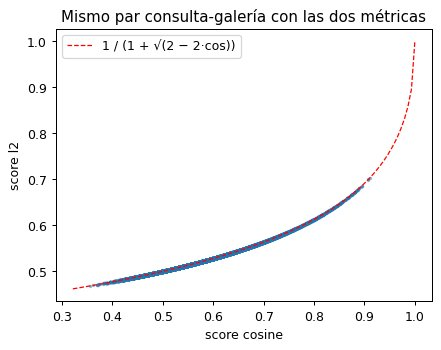

Consultas de test con el mismo Top-10 en las dos métricas: 100.0%


In [9]:
q = QUERIES["test"][0][:200]
c, l = score_matrix(q, "cosine").ravel(), score_matrix(q, "l2").ravel()
same_top = (np.argsort(-score_matrix(QUERIES["test"][0], "cosine"), 1)[:, :10]
            == np.argsort(-score_matrix(QUERIES["test"][0], "l2"), 1)[:, :10]).all(1).mean()
fig, ax = plt.subplots(figsize=(5, 4))
ax.scatter(c[::50], l[::50], s=3, alpha=0.4)
xs = np.linspace(c.min(), 1, 100)
ax.plot(xs, 1 / (1 + np.sqrt(2 - 2 * xs)), "r--", lw=1, label="1 / (1 + √(2 − 2·cos))")
ax.set_xlabel("score cosine")
ax.set_ylabel("score l2")
ax.set_title("Mismo par consulta-galería con las dos métricas")
ax.legend()
plt.tight_layout()
plt.show()
print(f"Consultas de test con el mismo Top-10 en las dos métricas: {same_top:.1%}")

### 5.5 Distribución del NDCG@10 y resultados por raza

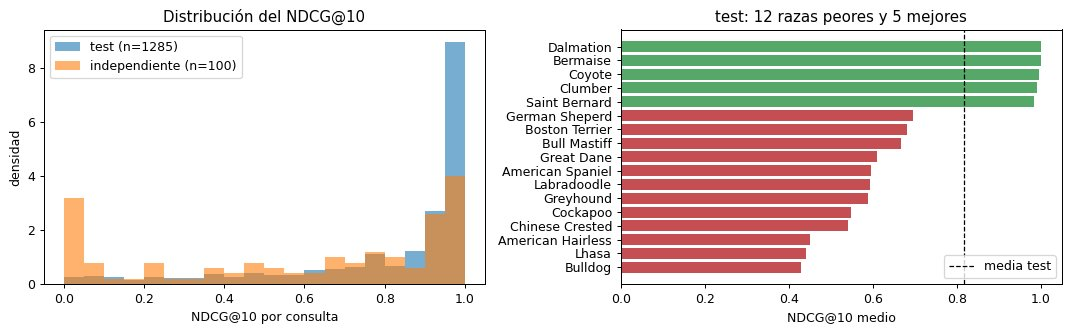

Fracción de consultas con NDCG@10 = 1: test 45.0% | independiente 20.0%
Fracción con NDCG@10 < 0.3: test 7.6% | independiente 27.0%


In [10]:
r_test, r_ind = RESULTS[("cosine", "test")], RESULTS[("cosine", "independiente")]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, 1, 21)
axes[0].hist(r_test["ndcg@10"], bins=bins, alpha=0.6, density=True, label=f"test (n={len(r_test)})")
axes[0].hist(r_ind["ndcg@10"], bins=bins, alpha=0.6, density=True, label=f"independiente (n={len(r_ind)})")
axes[0].set_xlabel("NDCG@10 por consulta")
axes[0].set_ylabel("densidad")
axes[0].set_title("Distribución del NDCG@10")
axes[0].legend()

per_breed = r_test.groupby("breed").agg(ndcg=("ndcg@10", "mean"), acc=("ok", "mean"), n=("ok", "size")).sort_values("ndcg")
sel = pd.concat([per_breed.head(12), per_breed.tail(5)])
axes[1].barh(sel.index, sel.ndcg, color=["#c44e52"] * 12 + ["#55a868"] * 5)
axes[1].axvline(r_test["ndcg@10"].mean(), color="k", ls="--", lw=1, label="media test")
axes[1].set_xlabel("NDCG@10 medio")
axes[1].set_title("test: 12 razas peores y 5 mejores")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

print("Fracción de consultas con NDCG@10 = 1:", f"test {(r_test['ndcg@10'] == 1).mean():.1%} |",
      f"independiente {(r_ind['ndcg@10'] == 1).mean():.1%}")
print("Fracción con NDCG@10 < 0.3:", f"test {(r_test['ndcg@10'] < 0.3).mean():.1%} |",
      f"independiente {(r_ind['ndcg@10'] < 0.3).mean():.1%}")

In [11]:
ind_breed = r_ind.groupby("breed").agg(n=("ok", "size"), ndcg=("ndcg@10", "mean"), acc=("ok", "mean"))
ind_breed = ind_breed.join(per_breed[["ndcg", "acc"]], rsuffix="_test").sort_values("ndcg")
ind_breed.columns = ["consultas", "NDCG@10 indep.", "accuracy indep.", "NDCG@10 test", "accuracy test"]
display(ind_breed.round(2))

,consultas,NDCG@10 indep.,accuracy indep.,NDCG@10 test,accuracy test
breed,,,,,
Poodle,3,0.17,0.33,0.76,0.83
Shih-Tzu,4,0.21,0.25,0.76,0.90
Shiba Inu,4,0.36,0.50,0.75,0.82
Chihuahua,5,0.38,0.40,0.92,1.00
French Bulldog,5,0.40,0.40,0.73,0.88
Dingo,2,0.41,0.50,0.79,0.90
Labrador,5,0.43,0.40,0.85,0.92
Border Collie,5,0.47,0.80,0.83,0.95
Bulldog,5,0.49,0.60,0.43,0.52


**Interpretación.**

- **Distribución:** en `test`, el 45% de las consultas tiene NDCG@10 = 1 (los 10 vecinos de la
  raza correcta) y solo el 7,6% queda por debajo de 0,3. En el conjunto independiente, el 20% es
  perfecto y el 27% queda por debajo de 0,3: la distribución es bimodal, o la búsqueda encuentra
  la raza o se va a otra.
- **Las razas peores de `test` son justamente los pares casi idénticos** que se vieron en la
  notebook 1 (sección 6.3): Bulldog (0,43), Lhasa (0,44), American Hairless (0,45), Chinese
  Crested, Cockapoo y Labradoodle. Las mejores son las de pelaje o color inconfundible
  (Dalmation y Bermaise con 1,0, Coyote, Clumber, Saint Bernard).
- **En el conjunto independiente el patrón es otro:** fallan Poodle (0,17), Shih-Tzu (0,21),
  Chihuahua (0,38) o Labrador (0,43), que en `test` andan bien (Chihuahua: 0,92). Esa caída viene
  del tipo de foto, no de confusión entre razas parecidas. Las que se sostienen (Dalmation,
  Golden Retriever, Doberman, Siberian Husky, Pug) tienen un color o un patrón de pelaje que
  se reconoce aunque cambie el encuadre. Con 2 a 5 imágenes por raza, estos valores por raza
  son orientativos.

### 5.6 Efecto de `TOP_K`

`TOP_K` es la cantidad de vecinos que votan la raza (el NDCG@10 siempre usa los 10 primeros).

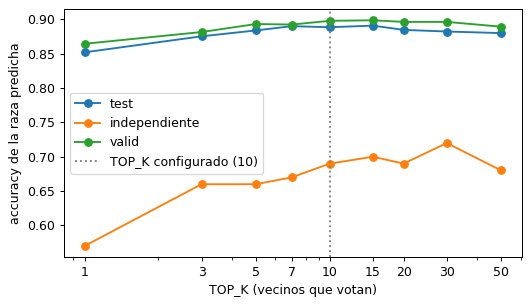

TOP_K,1,3,5,7,10,15,20,30,50
test,0.852,0.875,0.884,0.890,0.889,0.891,0.885,0.882,0.880
independiente,0.570,0.660,0.660,0.670,0.690,0.700,0.690,0.720,0.680
valid,0.865,0.882,0.893,0.893,0.898,0.899,0.896,0.896,0.889


In [12]:
KS = [1, 3, 5, 7, 10, 15, 20, 30, 50]
topk = pd.DataFrame({n: [evaluate(n, "cosine", k=k).ok.mean() for k in KS] for n in ("test", "independiente", "valid")}, index=KS)
topk.index.name = "TOP_K"
fig, ax = plt.subplots(figsize=(6, 3.5))
for n in topk:
    ax.plot(topk.index, topk[n], marker="o", label=n)
ax.axvline(settings.top_k, color="gray", ls=":", label=f"TOP_K configurado ({settings.top_k})")
ax.set_xscale("log")
ax.set_xticks(KS)
ax.set_xticklabels(KS)
ax.set_xlabel("TOP_K (vecinos que votan)")
ax.set_ylabel("accuracy de la raza predicha")
ax.legend()
plt.tight_layout()
plt.show()
display(topk.T.round(3))

**Interpretación.**

- **Con un solo vecino (`TOP_K = 1`) la accuracy es la más baja** (0,852 en `test`, 0,57 en el
  independiente): el vecino más cercano a veces es de una raza parecida y el voto lo corrige.
- **La accuracy sube hasta K ≈ 10–15 y después baja levemente en `test` y `valid`**
  (0,889 con 10, 0,880 con 50): con muchos vecinos entran imágenes de otras razas que votan.
- **Se mantiene `TOP_K = 10`:** está a menos de 0,2 puntos del máximo en `test` y en `valid`
  (la diferencia con K = 15 en `valid` es 1 consulta de 1285), coincide con el NDCG@10 y con las
  10 imágenes que muestra la interfaz. En el independiente la curva sube con K pero es ruidosa:
  cada imagen vale 1 punto.

### 5.7 Calibración de `SIMILARITY_THRESHOLD`

Si la similitud del vecino más cercano queda por debajo del umbral, el servicio devuelve
`unknown`. El objetivo es rechazar consultas que no se parecen a nada de la galería (por ejemplo,
una foto sin perro) sin rechazar perros de las razas conocidas.

**Criterio:** el umbral se calibra solo con `valid`, sin mirar test ni el conjunto independiente.
Se elige el percentil 0,1 del score top-1 de `valid` (redondeado hacia abajo a dos decimales): el
umbral más alto que rechaza como mucho 1 de cada 1000 perros de razas conocidas. Se prioriza no
rechazar perros porque, en la pestaña de la Etapa 1, un `unknown` sobre la foto de un perro es
peor que una raza dudosa sobre una foto sin perro (que además la Etapa 3 filtra con YOLO).
Después se mide, sin recalibrar, qué pasa con las fotos sin perro (`no_dog`), con las escenas de
varios perros (`multi_dog`) y con las fotos de razas del conjunto independiente.

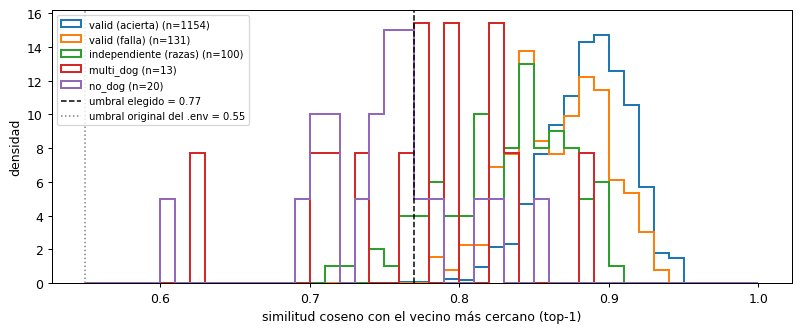

,valid rechazadas,accuracy valid (rechazo = error),indep. razas rechazadas,indep. rechazadas que estaban bien,accuracy indep. (rechazo = error),multi_dog rechazadas,no_dog rechazadas
umbral,,,,,,,
0.55,0.0%,89.8%,0.0%,0.0%,69.0%,0.0%,0.0%
0.70,0.0%,89.8%,0.0%,0.0%,69.0%,7.7%,10.0%
0.74,0.0%,89.8%,2.0%,0.0%,69.0%,30.8%,35.0%
0.76,0.0%,89.8%,5.0%,0.0%,69.0%,30.8%,60.0%
0.77,0.1%,89.7%,9.0%,0.0%,69.0%,38.5%,75.0%
0.78,0.2%,89.6%,13.0%,4.0%,65.0%,53.8%,80.0%
0.80,0.6%,89.4%,23.0%,8.0%,61.0%,69.2%,85.0%
0.82,2.1%,88.4%,37.0%,16.0%,53.0%,69.2%,90.0%
0.85,13.2%,80.2%,63.0%,36.0%,33.0%,92.3%,95.0%


SIMILARITY_THRESHOLD (cosine) = 0.77  |  equivalente en l2: 0.60


test con el umbral: 0.4% rechazadas, accuracy (rechazo = error) 0.887

Fotos sin perro que superan el umbral (Commons: categoría de origen):
                                            file                     category  top1
     no_dog/no_dog/Vulpes_vulpes_Mallnitz_04.jpg Sleeping cats; Vulpes vulpes 0.853
             no_dog/no_dog/Arabian_Red_Fox_1.jpg Sleeping cats; Vulpes vulpes 0.825
        no_dog/no_dog/Stanislaus_nach_der_OP.jpg Sleeping cats; Vulpes vulpes 0.819
no_dog/no_dog/Black_Cat_Sitia_Crete_Greece_2.jpg Sleeping cats; Vulpes vulpes 0.784
       no_dog/no_dog/Red_Fox_Vulpes_vulpes_4.jpg Sleeping cats; Vulpes vulpes 0.779


In [13]:
r_val = RESULTS[("cosine", "valid")]
S_scenes = {g: score_matrix(EMB["independent"][(SETS["independent"].group == g).to_numpy()], "cosine").max(1)
            for g in ("no_dog", "multi_dog")}
top1 = {
    "valid (acierta)": r_val.top1_score[r_val.ok].to_numpy(),
    "valid (falla)": r_val.top1_score[~r_val.ok].to_numpy(),
    "independiente (razas)": r_ind.top1_score.to_numpy(),
    "multi_dog": S_scenes["multi_dog"],
    "no_dog": S_scenes["no_dog"],
}
THRESHOLD = float(np.floor(np.percentile(r_val.top1_score, 0.1) * 100) / 100)

fig, ax = plt.subplots(figsize=(9, 3.8))
bins = np.linspace(0.55, 1.0, 46)
for name, v in top1.items():
    ax.hist(v, bins=bins, density=True, histtype="step", lw=1.6, label=f"{name} (n={len(v)})")
ax.axvline(THRESHOLD, color="k", ls="--", lw=1.2, label=f"umbral elegido = {THRESHOLD:.2f}")
ax.axvline(0.55, color="gray", ls=":", lw=1.2, label="umbral original del .env = 0.55")
ax.set_xlabel("similitud coseno con el vecino más cercano (top-1)")
ax.set_ylabel("densidad")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

rows = []
for thr in [0.55, 0.70, 0.74, 0.76, THRESHOLD, 0.78, 0.80, 0.82, 0.85]:
    keep_val, keep_ind = r_val.top1_score >= thr, r_ind.top1_score >= thr
    rows.append({
        "umbral": thr,
        "valid rechazadas": 1 - keep_val.mean(),
        "accuracy valid (rechazo = error)": (r_val.ok & keep_val).mean(),
        "indep. razas rechazadas": 1 - keep_ind.mean(),
        "indep. rechazadas que estaban bien": (r_ind.ok & ~keep_ind).mean(),
        "accuracy indep. (rechazo = error)": (r_ind.ok & keep_ind).mean(),
        "multi_dog rechazadas": (S_scenes["multi_dog"] < thr).mean(),
        "no_dog rechazadas": (S_scenes["no_dog"] < thr).mean(),
    })
thr_table = pd.DataFrame(rows).drop_duplicates("umbral").sort_values("umbral").set_index("umbral")
display(thr_table.style.format("{:.1%}").format_index("{:.2f}"))
print(f"SIMILARITY_THRESHOLD (cosine) = {THRESHOLD:.2f}  |  equivalente en l2: {1 / (1 + np.sqrt(2 - 2 * THRESHOLD)):.2f}")
r_test_thr = evaluate("test", "cosine", threshold=THRESHOLD)
print(f"test con el umbral: {(r_test_thr.pred == 'unknown').mean():.1%} rechazadas, accuracy (rechazo = error) {r_test_thr.ok.mean():.3f}")
nd = SETS["independent"][(SETS["independent"].group == "no_dog")].assign(top1=S_scenes["no_dog"])
print("\nFotos sin perro que superan el umbral (Commons: categoría de origen):")
print(nd[nd.top1 >= THRESHOLD].sort_values("top1", ascending=False)[["file", "category", "top1"]].round(3).to_string(index=False))

**Interpretación.**

- **El umbral original del `.env` (0,55) no rechaza nada:** el score top-1 de todas las consultas,
  incluso las fotos sin perro, está por encima de 0,60. Con embeddings de ImageNet, cualquier foto
  tiene algún vecino de la galería con similitud coseno alta.
- **Umbral elegido: 0,77** (percentil 0,1 de `valid`). Rechaza el 0,1% de `valid` y el 0,4% de
  `test`, donde la accuracy pasa de 0,889 a 0,887. Sin recalibrar:
  - rechaza el **75% de las fotos sin perro**;
  - rechaza el **9% de las fotos de razas del independiente, y las 9 eran consultas que la
    búsqueda ya clasificaba mal**: la accuracy del independiente sigue en 0,69 y esas fotos pasan
    de una raza equivocada a `unknown`;
  - rechaza el 38% de las escenas con varios perros, que mezclan razas y no se parecen a ningún
    recorte de la galería.
- **Subir el umbral tiene costo:** con 0,80 se rechaza el 85% de las fotos sin perro, pero ya se
  pierden fotos de perros que estaban bien clasificadas y la accuracy del independiente baja a
  0,61. Por eso se prioriza el percentil bajo.
- **Las 5 fotos sin perro que superan el umbral son 3 zorros y 2 gatos.** Los zorros son
  cánidos y la galería incluye cánidos salvajes (Coyote, Dhole, Dingo, African Wild Dog), así que
  su similitud alta es esperable. La similitud con un embedding de ImageNet no separa por completo
  "perro" de "no perro"; ese filtro lo hace el detector YOLO de la Etapa 3.
- **Configuración:** `SIMILARITY_THRESHOLD=0.77` en los `.env` (métrica `cosine`). Si se usara
  `l2`, el umbral equivalente es 0,60 (misma decisión, otra escala).

### 5.8 Análisis de errores con ejemplos

Pares de razas más confundidos en `test` (raza real → raza predicha) y ejemplos de consultas con
sus Top-10. Borde verde: vecino de la misma raza que la consulta; rojo: de otra raza.

Errores en test: 143 de 1285


,errores
Lhasa → Shih-Tzu,11
German Sheperd → Malinois,6
American Hairless → Mex Hairless,5
Bulldog → Boston Terrier,5
Cockapoo → Labradoodle,4
Chinese Crested → Chihuahua,3
Labradoodle → Cockapoo,3
Bull Mastiff → Rhodesian,2
Bulldog → Boxer,2
Bulldog → Bull Mastiff,2


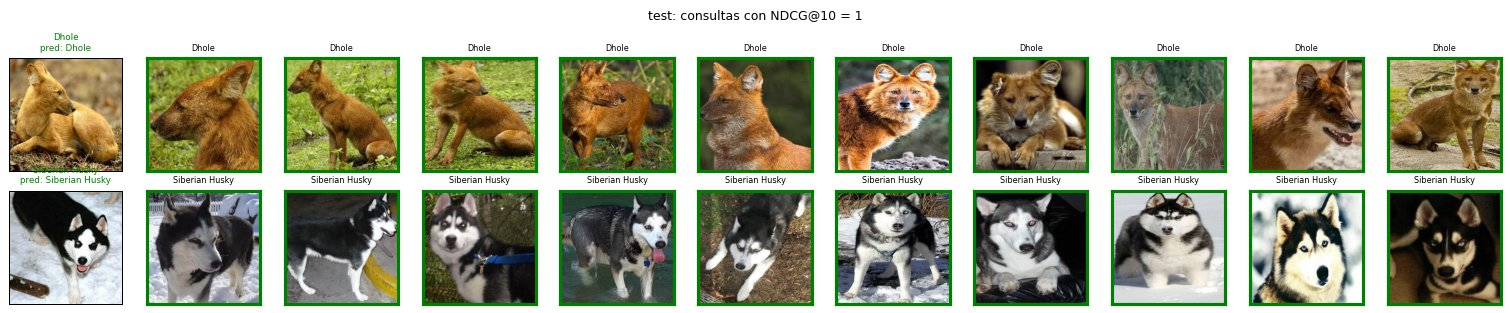

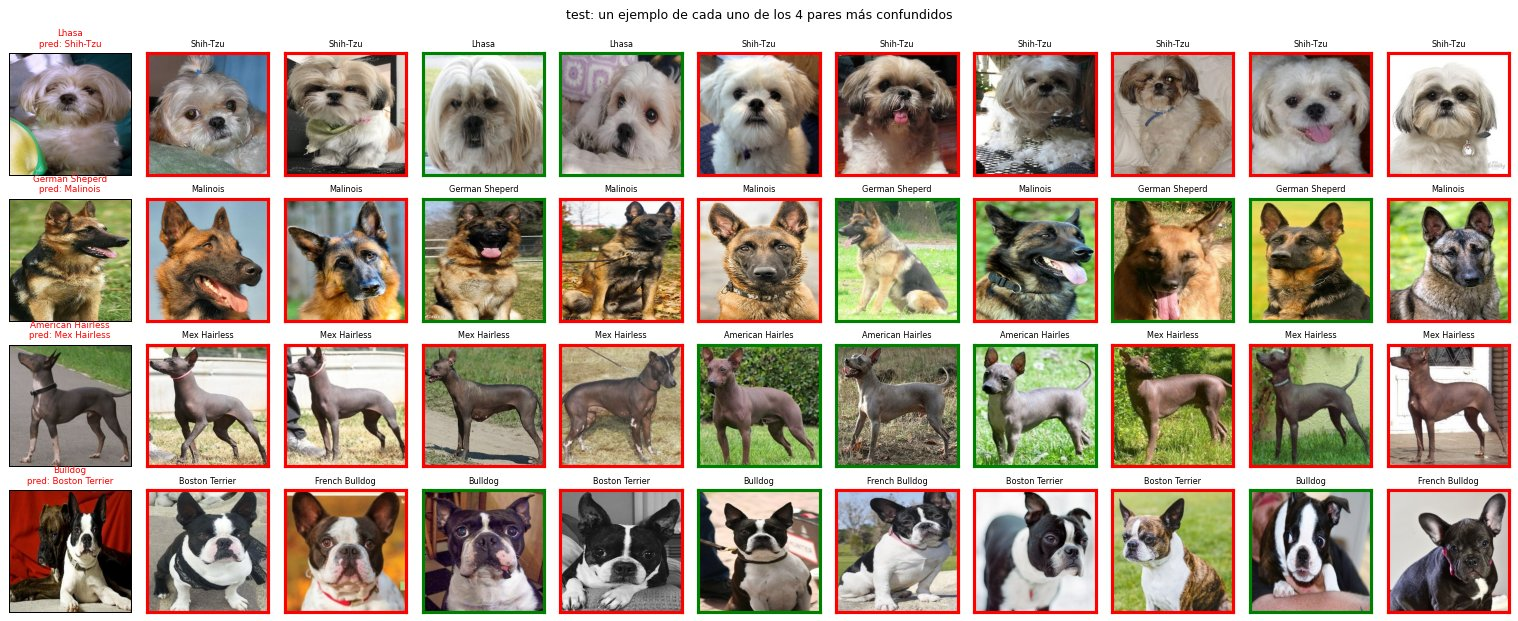

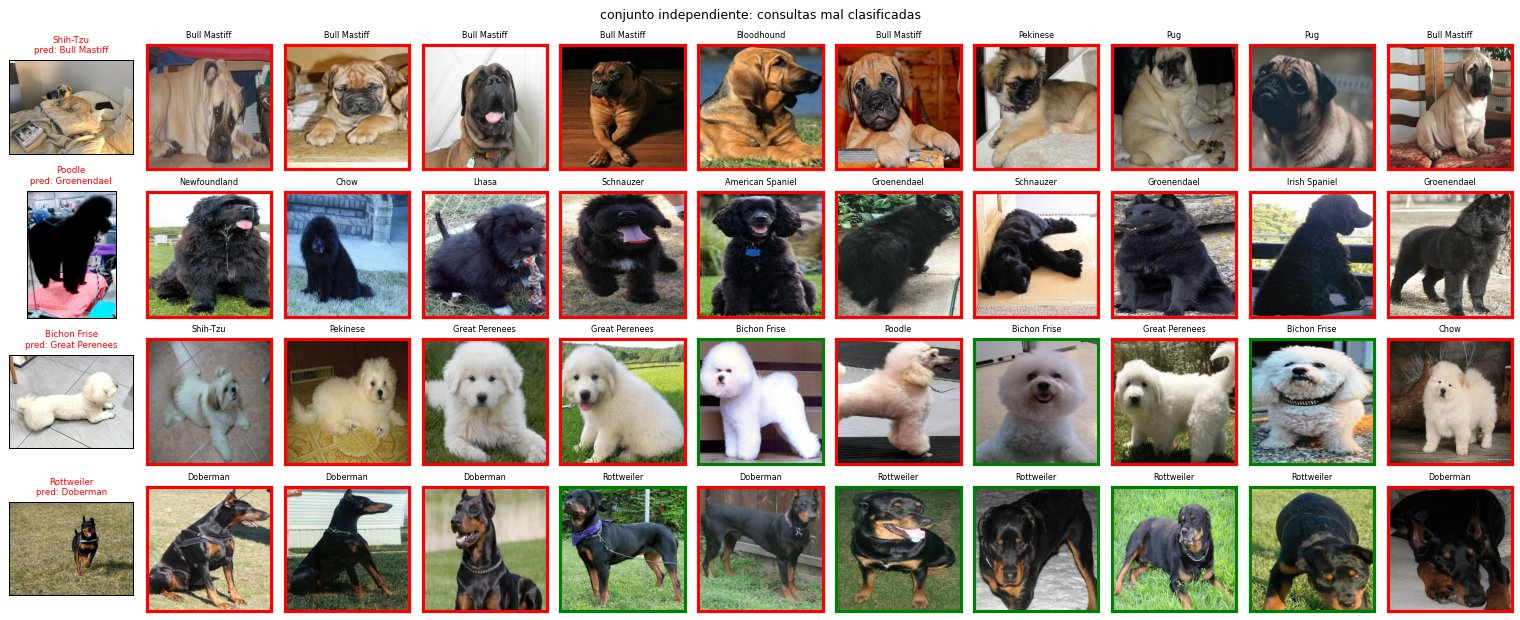

In [14]:
err = r_test[~r_test.ok]
pairs = (err.breed + "  →  " + err.pred).value_counts()
print(f"Errores en test: {len(err)} de {len(r_test)}")
display(pairs.head(12).rename("errores").to_frame())


def show_top10(rows, title):
    fig, axes = plt.subplots(len(rows), 11, figsize=(17, 1.75 * len(rows)))
    axes = np.atleast_2d(axes)
    for r, (_, row) in enumerate(rows.iterrows()):
        ax = axes[r, 0]
        ax.imshow(bgr_to_rgb(read_bgr(row.path)))
        ax.set_title(f"{row.breed}\npred: {row.pred}", fontsize=7, color="green" if row.ok else "red")
        for j, g in enumerate(row.top10):
            ax = axes[r, j + 1]
            ax.imshow(bgr_to_rgb(read_bgr(settings.dataset_path / G_PATH[g])))
            ok = G_BREED[g] == row.breed
            for s in ax.spines.values():
                s.set_edgecolor("green" if ok else "red")
                s.set_linewidth(2.5)
            ax.set_title(G_BREED[g][:16], fontsize=6.5)
    for ax in axes.ravel():
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


rng = np.random.default_rng(SEED)
good = r_test[r_test["ndcg@10"] == 1].sample(2, random_state=SEED)
show_top10(good, "test: consultas con NDCG@10 = 1")
worst_pairs = pairs.head(4).index
bad = pd.concat([err[(err.breed + "  →  " + err.pred) == p].sample(1, random_state=SEED) for p in worst_pairs])
show_top10(bad, "test: un ejemplo de cada uno de los 4 pares más confundidos")
show_top10(r_ind[~r_ind.ok].sample(4, random_state=SEED), "conjunto independiente: consultas mal clasificadas")

**Interpretación de los errores.**

- **Una cuarta parte de los errores de `test` (34 de 143) está en 5 pares de razas**
  (Lhasa → Shih-Tzu, German Sheperd → Malinois, American Hairless → Mex Hairless,
  Bulldog → Boston Terrier y Cockapoo ↔ Labradoodle), y el resto de la lista sigue el mismo
  patrón de razas emparentadas (Cairn → Scotch Terrier, Collie → Border Collie). Son razas que se diferencian por detalles (largo del hocico, largo del
  pelo, el manto negro del pastor alemán) que el embedding de ImageNet no prioriza: en la fila del
  Lhasa, los Shih-Tzu recuperados tienen el mismo pelaje y la misma cara.
- **La clase Bulldog del dataset es ruidosa:** en la cuarta fila, las imágenes etiquetadas
  "Bulldog" que se recuperan (borde verde) tienen orejas de murciélago y la máscara blanca y negra
  del Boston Terrier o del French Bulldog. Con etiquetas mezcladas, ningún embedding puede separar
  bien la clase; explica que Bulldog sea la peor raza de `test`.
- **En el conjunto independiente los errores son de otro tipo:**
  - **perro chico dentro de una foto amplia** (Shih-Tzu sobre una cama, Rottweiler en un campo):
    el embedding describe la escena entera y no al perro;
  - **el color domina:** el Poodle negro recupera perros negros de cualquier raza (Newfoundland,
    Chow, Schnauzer) y el Bichon Frise acostado recupera perros blancos y peludos;
  - **pose:** los perros acostados recuperan otros perros acostados (Bull Mastiff).
- **Qué sugiere:** el baseline codifica color, textura, pose y fondo además de la raza. El
  fine-tuning (Modelo A, sección 6) debería llevar el embedding a los rasgos que separan razas; y
  recortar al perro con YOLO antes de buscar (como hace la Etapa 3) acercaría las fotos completas
  al dominio de la galería.

### 5.9 Configuración elegida para la Etapa 1

| Parámetro | Valor | Justificación |
|---|---|---|
| Extractor (`EMBEDDING_MODEL`) | `baseline`: ResNet18 de ImageNet, 512 | Misma dimensión y arquitectura que el Modelo A; se compara con los modelos entrenados en la sección 9 |
| `SIMILARITY_METRIC` | `cosine` | Igual ranking que `l2` con embeddings normalizados (5.4); es la métrica que pgvector usa para ordenar (`<=>`) |
| `TOP_K` | 10 | A menos de 0,2 puntos del máximo de accuracy en test y valid (5.6) |
| `SIMILARITY_THRESHOLD` | 0,77 | Percentil 0,1 del score top-1 de valid; rechaza el 75% de las fotos sin perro sin perder aciertos en el independiente y con 0,2 puntos menos en test (5.7) |

Resultado del baseline: **NDCG@10 = 0,817 en `test` y 0,595 en el conjunto independiente**
(accuracy 0,889 y 0,69).

## 6. Modelo A (obligatorio): fine-tuning de ResNet

**Modelo:** ResNet18 preentrenado en ImageNet; la capa `fc` se reemplaza por `Dropout + Linear(512, 70)`
(`src/lib/models/resnet_classifier.py`). El embedding para la búsqueda es la salida del global
average pooling (512), la capa previa al clasificador.

**Se comparan dos estrategias** (enunciado 5.2), con el mismo preprocesamiento, augmentation y semilla:

| | *Feature extraction* | *Fine-tuning* completo |
|---|---|---|
| Qué se entrena | solo la cabeza (35.910 parámetros); backbone y BatchNorm congelados | todo el modelo (11,2 M) |
| Learning rate | 1e-3 | cabeza 1e-3, backbone 1e-4 (10x menor: los pesos de ImageNet ya son buenos y un lr alto los destruye) |
| Épocas máx. / paciencia | 10 / 5 | 15 / 5 |

**Hiperparámetros comunes** (`src/lib/models/train_config.py`): AdamW (`weight_decay` 1e-4), batch 64,
1 época de *warmup* lineal y después decaimiento coseno por paso, *label smoothing* 0,1 (hay pares de
razas casi idénticos; evita que el modelo se vuelva sobreconfiado con etiquetas que pueden estar
mal), dropout 0,2 antes de la capa final, augmentation de la notebook 1. Se guarda el modelo de la
época con mejor accuracy en `valid` (*early stopping*). En la GTX 1650 se entrena en fp32: la
precisión mixta (fp16) da NaN en estas GPUs (Turing sin *tensor cores*); en Colab (T4) se activa sola.

**Entrenamiento:** los modelos se entrenaron con estas mismas llamadas (`train_classifier` con
`train_overrides`), leyendo una copia del dataset en el disco de WSL (la lectura desde el disco
de Windows era 3,5 veces más lenta). Con `RETRAIN = False` la notebook usa los checkpoints de
`models/` (link de descarga en el README) y muestra el registro de cada época guardado en
`output/train/history_<run>.json`; con `RETRAIN = True` vuelve a entrenar todo (~1 h en una GTX 1650).

In [15]:
import json

from lib.bootstrap import build_classifier
from lib.models.train_config import get_config

RETRAIN = False
TRAIN_OUT = ROOT / "output" / "train"

classifier = build_classifier(settings)
classifier.output_path = TRAIN_OUT

RUNS_A = {
    "resnet18_feature_extraction": {"strategy": "feature_extraction", "epochs": 10,
                                    "checkpoint": str(settings.model_path / "resnet18_feature_extraction.pth")},
    "resnet18_finetuned": {},
}
RUNS_B = {
    "cnn_e1_sin_aug_sin_residual": {"augment": False, "residual": False,
                                    "checkpoint": str(settings.model_path / "experiments" / "cnn_e1.pth")},
    "cnn_e2_aug_sin_residual": {"augment": True, "residual": False,
                                "checkpoint": str(settings.model_path / "experiments" / "cnn_e2.pth")},
    "cnn_custom": {},
}


def train_or_load(model_name, runs):
    histories = {}
    for run, overrides in runs.items():
        hist_file = TRAIN_OUT / f"history_{run}.json"
        if RETRAIN or not hist_file.exists():
            classifier.set_active_model(model_name)
            classifier.train_overrides = {**overrides, "run_name": run}
            classifier.train_classifier()
        histories[run] = json.loads(hist_file.read_text(encoding="utf-8"))
    classifier.train_overrides = {}
    return histories


def print_log(h):
    print(f"[{h['run_name']}] {h['params']:,} parámetros ({h['trainable_params']:,} entrenables), "
          f"{h['train_seconds'] / 60:.1f} min")
    for r in h["history"]:
        best = " *" if r["epoch"] == h["best_epoch"] else ""
        print(f"  época {r['epoch']:3d} | train loss {r['train_loss']:.3f} acc {r['train_acc']:.3f} | "
              f"valid loss {r['val_loss']:.3f} acc {r['val_acc']:.3f}{best} | {r['seconds']:.0f} s")


HIST_A = train_or_load("resnet18_finetuned", RUNS_A)
for h in HIST_A.values():
    print_log(h)

[resnet18_feature_extraction] 11,212,422 parámetros (35,910 entrenables), 2.5 min
  época   1 | train loss 3.621 acc 0.212 | valid loss 2.135 acc 0.747 | 31 s
  época   2 | train loss 1.787 acc 0.752 | valid loss 1.374 acc 0.868 | 13 s
  época   3 | train loss 1.449 acc 0.831 | valid loss 1.271 acc 0.882 | 13 s
  época   4 | train loss 1.366 acc 0.855 | valid loss 1.236 acc 0.895 | 13 s
  época   5 | train loss 1.329 acc 0.866 | valid loss 1.225 acc 0.897 | 13 s
  época   6 | train loss 1.307 acc 0.876 | valid loss 1.222 acc 0.894 | 13 s
  época   7 | train loss 1.285 acc 0.883 | valid loss 1.207 acc 0.904 | 13 s
  época   8 | train loss 1.271 acc 0.888 | valid loss 1.201 acc 0.905 | 13 s
  época   9 | train loss 1.274 acc 0.885 | valid loss 1.199 acc 0.907 * | 13 s
  época  10 | train loss 1.263 acc 0.889 | valid loss 1.199 acc 0.907 | 13 s
[resnet18_finetuned] 11,212,422 parámetros (11,212,422 entrenables), 8.3 min
  época   1 | train loss 3.294 acc 0.305 | valid loss 1.583 acc 0.808

In [16]:
def runs_table(histories):
    rows = []
    for run, h in histories.items():
        last = h["history"][-1]
        best = h["history"][h["best_epoch"] - 1]
        rows.append({"run": run, "parámetros entrenables": h["trainable_params"], "épocas corridas": last["epoch"],
                     "mejor época": h["best_epoch"], "train acc (mejor época)": best["train_acc"],
                     "valid acc (mejor época)": best["val_acc"], "valid loss": best["val_loss"],
                     "minutos": h["train_seconds"] / 60})
    return pd.DataFrame(rows).set_index("run")


display(runs_table(HIST_A).round(3))

,parámetros entrenables,épocas corridas,mejor época,train acc (mejor época),valid acc (mejor época),valid loss,minutos
run,,,,,,,
resnet18_feature_extraction,35910,10,9,0.885,0.907,1.199,2.468
resnet18_finetuned,11212422,15,10,0.983,0.915,1.087,8.322


**Interpretación: *feature extraction* vs. *fine-tuning*.**

- **Las dos estrategias llegan a valores casi iguales en `valid`:** 90,7% entrenando solo la cabeza
  (35.910 parámetros, 2,5 min) y **91,5%** con *fine-tuning* completo (11,2 M, 8,3 min). La
  diferencia es de 0,8 puntos, unas 10 imágenes de 1285. Los pesos de ImageNet ya separan bien las
  razas (ImageNet incluye ~120 razas de perros), y por eso con solo la capa final se obtiene casi
  todo el rendimiento.
- **El *fine-tuning* aprende más de train de lo que generaliza:** llega a 98% en train contra
  91,5% en valid, mientras que el *feature extraction* queda en 89% / 91% (no puede memorizar con
  tan pocos parámetros). Igual la pérdida de valid del *fine-tuning* no sube: el learning rate
  diferenciado, el *label smoothing* y el decaimiento coseno lo contienen.
- **Se elige el *fine-tuning* como Modelo A** (`resnet18_finetuned.pth`) por ser el mejor en
  `valid`, que es el criterio fijado antes de mirar test. El *feature extraction* sería una
  alternativa razonable si el costo de entrenamiento importara: rinde casi lo mismo en un tercio
  del tiempo.

In [17]:
classifier.set_active_model("resnet18_finetuned")
metrics_a = classifier.evaluate_classifier()
metrics_a

{'accuracy': 0.9058365758754864,
 'precision': 0.9101687232370558,
 'recall': 0.9089919420091981,
 'specificity': 0.9986336881213309,
 'f1': 0.9078259033029972}

### Curvas de entrenamiento y matriz de confusión (Modelo A)

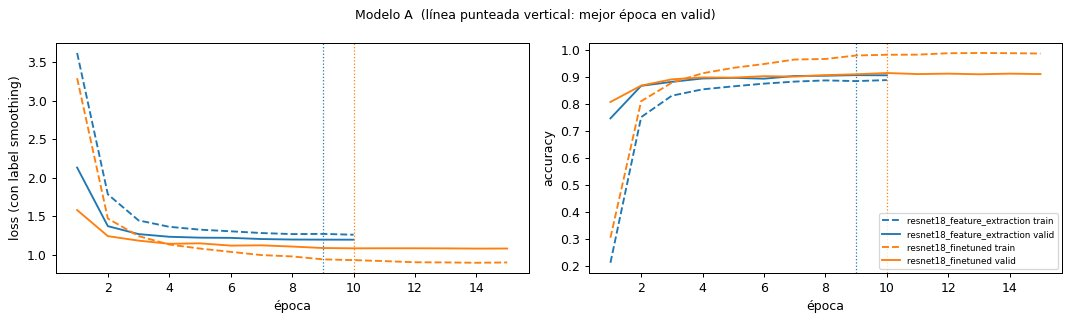

In [18]:
def plot_curves(histories, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
    for (run, h), color in zip(histories.items(), plt.cm.tab10.colors):
        ep = [r["epoch"] for r in h["history"]]
        for ax, key in zip(axes, ("loss", "acc")):
            ax.plot(ep, [r[f"train_{key}"] for r in h["history"]], "--", color=color, label=f"{run} train")
            ax.plot(ep, [r[f"val_{key}"] for r in h["history"]], "-", color=color, label=f"{run} valid")
            ax.axvline(h["best_epoch"], color=color, ls=":", lw=1)
    axes[0].set_ylabel("loss (con label smoothing)")
    axes[1].set_ylabel("accuracy")
    for ax in axes:
        ax.set_xlabel("época")
    axes[1].legend(fontsize=7, loc="lower right")
    fig.suptitle(title + "  (línea punteada vertical: mejor época en valid)", fontsize=10)
    plt.tight_layout()
    plt.show()


plot_curves(HIST_A, "Modelo A")

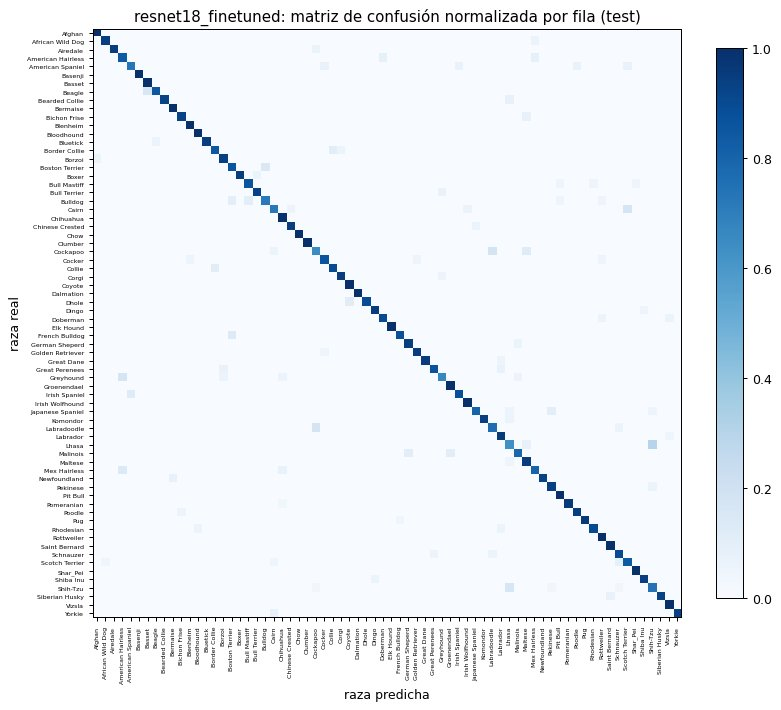

Pares más confundidos (test):


raza real,predicha,errores,% de la raza real
Lhasa,Shih-Tzu,8,30%
Shih-Tzu,Lhasa,5,16%
Labradoodle,Cockapoo,3,18%
Greyhound,American Hairless,3,17%
Cockapoo,Labradoodle,3,18%
Cairn,Scotch Terrier,3,17%
Beagle,Basset,3,15%
Malinois,Groenendael,2,11%
Mex Hairless,American Hairless,2,13%
Dhole,Coyote,2,11%


Las 10 razas con peor F1 (test):


,precision,recall,specificity,f1,support
Lhasa,0.654,0.630,0.993,0.642,27.0
Cockapoo,0.688,0.647,0.996,0.667,17.0
Shih-Tzu,0.697,0.742,0.992,0.719,31.0
American Hairless,0.667,0.833,0.996,0.741,12.0
Greyhound,0.857,0.667,0.998,0.750,18.0
Cairn,0.812,0.722,0.998,0.765,18.0
Labradoodle,0.765,0.765,0.997,0.765,17.0
American Spaniel,0.846,0.733,0.998,0.786,15.0
Bulldog,0.882,0.714,0.998,0.789,21.0
Boston Terrier,0.750,0.857,0.997,0.800,14.0


In [19]:
def load_eval(model_name):
    d = np.load(TRAIN_OUT / f"eval_{model_name}_test.npz")
    return d["y_true"], d["probs"], [str(c) for c in d["classes"]], [str(p) for p in d["paths"]]


def confusion_report(model_name, top=12):
    y_true, probs, classes, _ = load_eval(model_name)
    y_pred = probs.argmax(1)
    pc = classifier._per_class_metrics(y_true, y_pred, len(classes))
    cm = pc["confusion"]
    cm_norm = cm / cm.sum(1, keepdims=True)
    fig, ax = plt.subplots(figsize=(9, 8))
    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(classes)))
    ax.set_yticks(range(len(classes)))
    ax.set_xticklabels(classes, rotation=90, fontsize=5)
    ax.set_yticklabels(classes, fontsize=5)
    ax.set_xlabel("raza predicha")
    ax.set_ylabel("raza real")
    ax.set_title(f"{model_name}: matriz de confusión normalizada por fila (test)")
    plt.colorbar(im, fraction=0.04)
    plt.tight_layout()
    plt.show()
    off = cm.copy()
    np.fill_diagonal(off, 0)
    i, j = np.unravel_index(np.argsort(-off, axis=None)[:top], off.shape)
    pairs = pd.DataFrame({"raza real": [classes[a] for a in i], "predicha": [classes[b] for b in j],
                          "errores": off[i, j], "% de la raza real": off[i, j] / cm.sum(1)[i]})
    per_class = pd.DataFrame({k: pc[k] for k in ("precision", "recall", "specificity", "f1", "support")},
                             index=classes).sort_values("f1")
    return pairs[pairs.errores > 0], per_class


pairs_a, per_class_a = confusion_report("resnet18_finetuned")
print("Pares más confundidos (test):")
display(pairs_a.style.format({"% de la raza real": "{:.0%}"}).hide(axis="index"))
print("Las 10 razas con peor F1 (test):")
display(per_class_a.head(10).round(3))

**Interpretación (Modelo A en `test`).**

- **Accuracy 0,906 y F1 macro 0,908**, con precision y recall parejos (0,910 / 0,909): no hay un
  sesgo hacia algunas clases. La especificidad (0,999) es alta en cualquier modelo con 70 clases,
  porque cada clase one-vs-rest tiene muchísimos negativos; no discrimina entre modelos.
- **Las curvas:** la accuracy de valid se estabiliza desde la época 6 (~0,90) mientras la de train
  sigue subiendo hasta 0,99. Hay sobreajuste moderado, pero el early stopping toma la época 10 y
  las épocas siguientes no empeoran valid.
- **Los errores se concentran en los mismos pares que la Etapa 1:** Lhasa ↔ Shih-Tzu (13 errores
  entre los dos sentidos), Cockapoo ↔ Labradoodle, Cairn → Scotch Terrier, Collie → Border Collie,
  las dos razas sin pelo. La matriz de confusión es casi diagonal y los errores son puntos aislados
  entre razas emparentadas.
- **Respecto de la búsqueda del baseline** (accuracy 0,889 en test), el clasificador gana 1,7
  puntos. El salto es chico porque el baseline ya era bueno; donde más mejora es en razas que el
  embedding de ImageNet mezclaba: Bulldog pasa de 0,43 de NDCG en la Etapa 1 a F1 0,79.

## 7. Modelo B (obligatorio): CNN propia

Arquitectura en `src/lib/models/cnn_custom.py` (módulo importable: el checkpoint guarda el modelo
completo y `torch.load` necesita la clase).

| Etapa | Capas | Salida |
|---|---|---|
| Stem | conv 3×3 stride 2 (3→32) + BN + ReLU, max pool 2 | 32 × 56 × 56 |
| Bloque 1 | [conv 3×3 + BN + ReLU] × 2 (32→64) + atajo 1×1, max pool 2 | 64 × 28 × 28 |
| Bloque 2 | ídem (64→128), max pool 2 | 128 × 14 × 14 |
| Bloque 3 | ídem (128→256), max pool 2 | 256 × 7 × 7 |
| Bloque 4 | ídem (256→512) | 512 × 7 × 7 |
| Global average pooling | | 512 |
| Embedding | Linear(512, 512) + BN + ReLU | **512** (= `EMBEDDING_DIM`) |
| Clasificador | Dropout 0,3 + Linear(512, 70) | 70 logits |

**Justificación:**
- **Profundidad (stem + 4 bloques, 9 convoluciones):** lo sugerido por el enunciado (4–6 bloques).
  El campo receptivo final cubre toda la imagen, y la red es lo bastante chica (5,2 M de parámetros)
  para entrenarse desde cero con 6000 imágenes.
- **Stem con stride 2 y max pool:** baja a 56 × 56 antes de los bloques; las capas de alta
  resolución son las más costosas y con 224 px no hace falta tanto detalle temprano. Queda en
  ~0,7 GFLOPs por imagen, menos de la mitad que ResNet18.
- **BatchNorm después de cada convolución:** estabiliza el entrenamiento desde cero y permite un
  learning rate alto (2e-3).
- **Atajos residuales:** facilitan el flujo del gradiente; se comparan con y sin (experimentos).
- **Global average pooling en lugar de aplanar:** aplanar 512 × 7 × 7 llevaría la capa densa a
  ~12 M de parámetros, más que todo el resto de la red, y sobreajustaría.
- **Capa de embedding de 512** antes del clasificador: la usa la búsqueda por similitud.
- **Regularización más fuerte que en el Modelo A** (dropout 0,3, `weight_decay` 5e-4, label
  smoothing 0,1, 60 épocas con paciencia 12): sin preentrenamiento, el riesgo de sobreajuste es mayor.

**Experimentos** (mismo presupuesto de 60 épocas y misma semilla): E1 sin augmentation y sin
atajos residuales; E2 con augmentation; E3 (final) con augmentation y atajos residuales.

In [20]:
from lib.models.cnn_custom import DogCNN

cfg_b = get_config("cnn_custom")
cnn_preview = DogCNN([f"c{i}" for i in range(70)], widths=tuple(cfg_b["widths"]),
                     embedding_dim=cfg_b["embedding_dim"], dropout=cfg_b["dropout"], residual=cfg_b["residual"])
rows = []
for name, module in [("stem", cnn_preview.stem)] + [(f"features.{i}", m) for i, m in enumerate(cnn_preview.features)] + \
        [("pool", cnn_preview.pool), ("embedding", cnn_preview.embedding), ("classifier", cnn_preview.classifier)]:
    rows.append({"capa": name, "tipo": type(module).__name__, "parámetros": sum(p.numel() for p in module.parameters())})
summary_b = pd.DataFrame(rows)
x = torch.zeros(1, 3, settings.image_size, settings.image_size)
shapes = []
with torch.no_grad():
    cnn_preview.eval()
    h = cnn_preview.stem(x)
    shapes.append(tuple(h.shape[1:]))
    for m in cnn_preview.features:
        h = m(h)
        shapes.append(tuple(h.shape[1:]))
    e = cnn_preview.embed(x)
    shapes += [(512,), tuple(e.shape[1:]), (70,)]
summary_b["salida"] = shapes
display(summary_b)
print(f"Total: {summary_b['parámetros'].sum():,} parámetros")

,capa,tipo,parámetros,salida
0,stem,Sequential,928,"(32, 56, 56)"
1,features.0,ConvBlock,57728,"(64, 56, 56)"
2,features.1,MaxPool2d,0,"(64, 28, 28)"
3,features.2,ConvBlock,230144,"(128, 28, 28)"
4,features.3,MaxPool2d,0,"(128, 14, 14)"
5,features.4,ConvBlock,919040,"(256, 14, 14)"
6,features.5,MaxPool2d,0,"(256, 7, 7)"
7,features.6,ConvBlock,3673088,"(512, 7, 7)"
8,pool,AdaptiveAvgPool2d,0,"(512,)"
9,embedding,Sequential,263168,"(512,)"


Total: 5,180,006 parámetros


In [21]:
HIST_B = train_or_load("cnn_custom", RUNS_B)
for h in HIST_B.values():
    print_log(h)

[cnn_e1_sin_aug_sin_residual] 5,004,006 parámetros (5,004,006 entrenables), 14.4 min
  época   1 | train loss 3.972 acc 0.074 | valid loss 3.867 acc 0.104 | 16 s
  época   2 | train loss 3.633 acc 0.122 | valid loss 3.910 acc 0.094 | 15 s
  época   3 | train loss 3.412 acc 0.171 | valid loss 5.136 acc 0.060 | 14 s
  época   4 | train loss 3.166 acc 0.228 | valid loss 3.478 acc 0.163 | 14 s
  época   5 | train loss 2.937 acc 0.294 | valid loss 3.248 acc 0.237 | 14 s
  época   6 | train loss 2.694 acc 0.372 | valid loss 3.655 acc 0.187 | 14 s
  época   7 | train loss 2.482 acc 0.437 | valid loss 3.524 acc 0.240 | 14 s
  época   8 | train loss 2.266 acc 0.499 | valid loss 2.869 acc 0.350 | 14 s
  época   9 | train loss 2.081 acc 0.561 | valid loss 2.828 acc 0.357 | 14 s
  época  10 | train loss 1.908 acc 0.627 | valid loss 2.850 acc 0.355 | 14 s
  época  11 | train loss 1.713 acc 0.702 | valid loss 2.975 acc 0.345 | 14 s
  época  12 | train loss 1.540 acc 0.771 | valid loss 3.021 acc 0.36

In [22]:
exp_b = runs_table(HIST_B)
exp_b.insert(0, "augmentation", [HIST_B[r]["config"]["augment"] for r in exp_b.index])
exp_b.insert(1, "residual", [HIST_B[r]["config"]["residual"] for r in exp_b.index])
display(exp_b.round(3))

,augmentation,residual,parámetros entrenables,épocas corridas,mejor época,train acc (mejor época),valid acc (mejor época),valid loss,minutos
run,,,,,,,,,
cnn_e1_sin_aug_sin_residual,False,False,5004006,60,51,1.000,0.639,2.108,14.358
cnn_e2_aug_sin_residual,True,False,5004006,60,53,0.980,0.753,1.559,14.375
cnn_custom,True,True,5180006,60,52,0.991,0.777,1.526,16.890


**Interpretación de los experimentos (Modelo B).**

| Experimento | Cambio | Valid acc | Train acc | Qué muestra |
|---|---|---|---|---|
| E1 | sin augmentation, sin atajos residuales | 0,639 | 1,000 | Memoriza train en 19 épocas; después valid no mejora |
| E2 | + augmentation | 0,753 | 0,980 | **+11,4 puntos**: la decisión que más pesa |
| E3 (final) | + atajos residuales | **0,777** | 0,991 | +2,4 puntos más, con 176 k parámetros extra (1×1) |

- **Sin augmentation la red sobreajusta enseguida:** en E1 la accuracy de train llega a 99,6% en
  la época 19 y la pérdida de valid se estanca en 2,1; con 6000 imágenes y 5 M de parámetros, la
  red puede aprenderse cada imagen. La augmentation lo frena: en E2 y E3 train sube más despacio y
  valid sigue mejorando hasta la época ~52.
- **Los atajos residuales** dan una mejora menor pero consistente (E3 queda por encima de E2 en
  casi todas las épocas desde la ~25).
- **Qué no se probó por tiempo** (cada experimento lleva ~15 min en la GTX 1650): una red más
  ancha o más profunda, o augmentation más fuerte. Las curvas de E3 sugieren que el límite es la
  cantidad de datos y no la capacidad: train ya llega a 99% y la brecha con valid (21 puntos) es
  sobreajuste, no falta de capacidad. Más parámetros probablemente agrandarían la brecha.

In [23]:
classifier.set_active_model("cnn_custom")
metrics_b = classifier.evaluate_classifier()
metrics_b

{'accuracy': 0.7618677042801556,
 'precision': 0.7693297508697491,
 'recall': 0.7610252079387347,
 'specificity': 0.9965472910632974,
 'f1': 0.759806060493878}

### Curvas de entrenamiento y matriz de confusión (Modelo B)

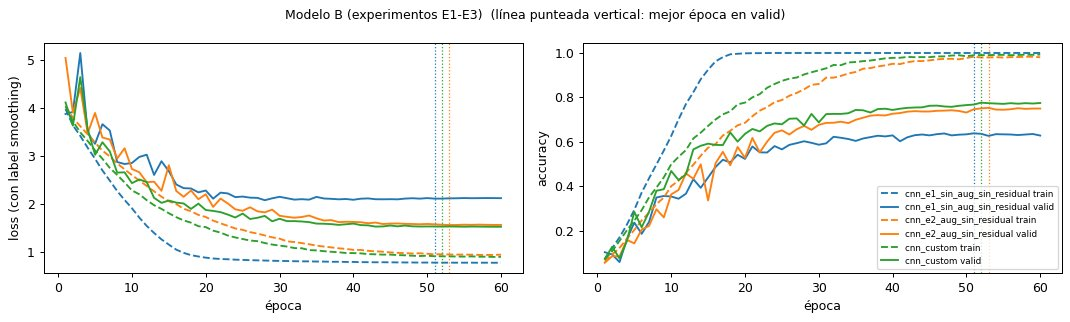

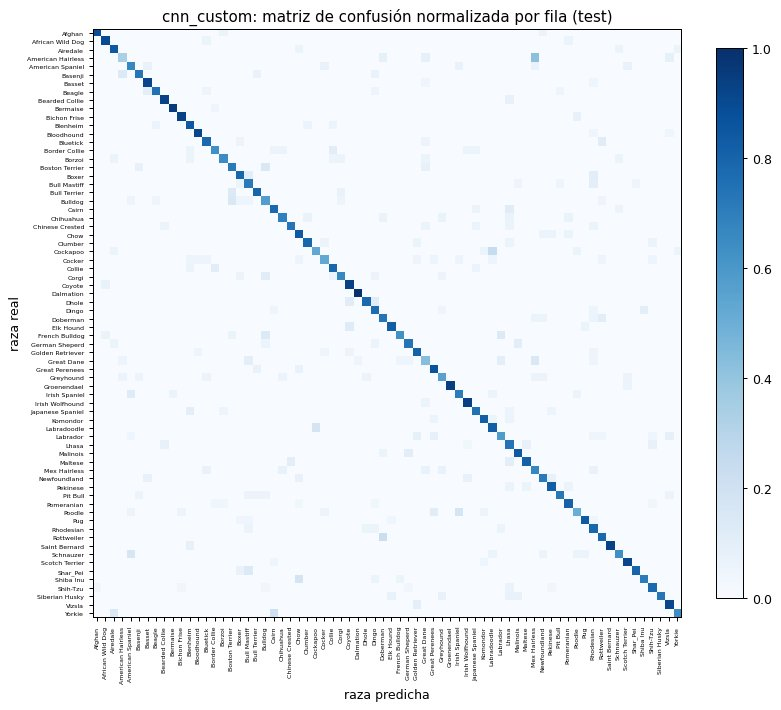

Pares más confundidos (test):


raza real,predicha,errores,% de la raza real
American Hairless,Mex Hairless,5,42%
Rottweiler,Doberman,4,22%
Cockapoo,Labradoodle,4,24%
Yorkie,Cairn,3,21%
Poodle,Irish Spaniel,3,17%
Labradoodle,Cockapoo,3,18%
Schnauzer,American Spaniel,3,16%
Shiba Inu,Chow,3,18%
Great Dane,Mex Hairless,3,14%
Bulldog,Boston Terrier,3,14%


Las 10 razas con peor F1 (test):


,precision,recall,specificity,f1,support
American Hairless,0.500,0.333,0.997,0.400,12.0
Great Dane,0.529,0.429,0.994,0.474,21.0
Mex Hairless,0.476,0.667,0.991,0.556,15.0
Bulldog,0.571,0.571,0.993,0.571,21.0
Poodle,0.692,0.500,0.997,0.581,18.0
Greyhound,0.667,0.556,0.996,0.606,18.0
American Spaniel,0.556,0.667,0.994,0.606,15.0
Cocker,0.733,0.524,0.997,0.611,21.0
Cockapoo,0.750,0.529,0.998,0.621,17.0
Rhodesian,0.517,0.789,0.989,0.625,19.0


In [24]:
plot_curves(HIST_B, "Modelo B (experimentos E1-E3)")
pairs_b, per_class_b = confusion_report("cnn_custom")
print("Pares más confundidos (test):")
display(pairs_b.style.format({"% de la raza real": "{:.0%}"}).hide(axis="index"))
print("Las 10 razas con peor F1 (test):")
display(per_class_b.head(10).round(3))

**Interpretación (Modelo B en `test`).**

- **Accuracy 0,762 y F1 macro 0,760:** 14 puntos por debajo del Modelo A. Es lo esperable para una
  red desde cero con 6000 imágenes de 70 razas (~85 por raza): el Modelo A parte de pesos
  entrenados con 1,2 M de imágenes de ImageNet, que ya codifican bordes, texturas, partes de
  animales e incluso razas de perros. La CNN propia tiene que aprender todo eso con 85 ejemplos
  por clase, y lo que aprende es en buena parte específico de train (99% vs. 78%).
- **Sus errores son más "visuales" que los del Modelo A:** además de los pares de razas
  emparentadas (American Hairless → Mex Hairless en el 42% de los casos, Cockapoo ↔ Labradoodle),
  confunde razas que solo comparten color o pelaje (Rottweiler → Doberman, Great Dane → Mex
  Hairless, Shiba Inu → Chow, Poodle → Great Perenees). Sin preentrenamiento, la red se apoya más
  en el color y la textura que en la forma.

## 8. Evaluación sobre el conjunto independiente

Las 100 fotos de razas del conjunto independiente (24 razas), con las mismas métricas. Precision,
recall, F1 y especificidad se promedian sobre las 24 razas presentes (una raza que no está en el
conjunto no tiene positivos: su recall no está definido).

In [25]:
IND = SETS["independent"][SETS["independent"].group == "breed"].reset_index(drop=True)
MODELS = {"resnet18_finetuned": "Modelo A (ResNet18 fine-tuned)", "cnn_custom": "Modelo B (CNN propia)"}
EVAL = {}
for m in MODELS:
    classifier.set_active_model(m)
    classes = classifier.load_model().classes
    y_ind = np.array([classes.index(b) for b in IND.label])
    probs_ind, _ = classifier._infer_paths(IND.abs_path.tolist())
    y_test, probs_test, _, _ = load_eval(m)
    EVAL[m] = {"classes": classes, "test": (y_test, probs_test), "independiente": (y_ind, probs_ind)}

rows = []
for m, d in EVAL.items():
    for split in ("test", "independiente"):
        y, p = d[split]
        rows.append({"modelo": MODELS[m], "conjunto": split, "imágenes": len(y),
                     **classifier._summary_metrics(y, p.argmax(1), len(d["classes"])),
                     "confianza media": p.max(1).mean()})
metrics_table = pd.DataFrame(rows).set_index(["modelo", "conjunto"])
display(metrics_table.round(3))

imágenes  accuracy  precision  recall  specificity     f1  confianza media
modelo                         conjunto                                                                                 
Modelo A (ResNet18 fine-tuned) test               1285     0.906      0.910   0.909        0.999  0.908            0.758
                               independiente       100     0.570      0.799   0.587        0.993  0.636            0.473
Modelo B (CNN propia)          test               1285     0.762      0.769   0.761        0.997  0.760            0.613
                               independiente       100     0.270      0.498   0.288        0.991  0.320            0.353

In [26]:
rows = []
for m, d in EVAL.items():
    y, p = d["independiente"]
    pred = p.argmax(1)
    df = pd.DataFrame({"raza": IND.label, "ok": pred == y})
    rows.append(df.groupby("raza").ok.mean().rename(MODELS[m]))
ind_breed_cls = pd.concat(rows, axis=1)
ind_breed_cls.insert(0, "imágenes", IND.label.value_counts())
display(ind_breed_cls.sort_values(MODELS["resnet18_finetuned"]).round(2).T)

raza,Shih-Tzu,Malinois,Maltese,Golden Retriever,Poodle,Boxer,French Bulldog,Chihuahua,Labrador,Lhasa,...,German Sheperd,Bichon Frise,Corgi,Border Collie,Bulldog,Doberman,Dingo,Collie,Pug,Siberian Husky
imágenes,4.0,5.0,4.00,3.00,3.00,5.0,5.0,5.0,5.0,4.00,...,3.00,4.00,4.00,5.0,5.0,5.0,2.0,2.0,3.0,5.0
Modelo A (ResNet18 fine-tuned),0.0,0.2,0.25,0.33,0.33,0.4,0.4,0.4,0.4,0.50,...,0.67,0.75,0.75,0.8,0.8,0.8,1.0,1.0,1.0,1.0
Modelo B (CNN propia),0.0,0.0,0.00,0.33,0.33,0.0,0.2,0.2,0.0,0.25,...,0.00,0.00,0.75,0.2,0.4,0.6,0.5,0.5,1.0,0.6


**Interpretación: cambio de dominio.**

- **Los dos modelos caen mucho en el conjunto independiente:** el Modelo A pasa de 0,906 a
  **0,57** de accuracy y el Modelo B de 0,762 a **0,27**. La confianza media también baja (de 0,76 a
  0,47 en el Modelo A): el modelo está menos seguro con estas fotos.
- **La causa es el tipo de foto, no las razas:** el dataset son recortes centrados del perro y el
  conjunto independiente son fotos completas, con fondo, personas, perros chicos o en movimiento
  (ver los ejemplos de la sección 10). Fallan en todas las fotos de Shih-Tzu y en la mayoría de
  Malinois y Maltese, y aciertan siempre Pug, Siberian Husky o Collie, de aspecto inconfundible.
- **El Modelo A clasifica peor que la búsqueda del baseline en este conjunto** (0,57 contra 0,69
  de la sección 5). El *fine-tuning* adaptó el modelo a los recortes del dataset y perdió parte de
  la robustez de los pesos de ImageNet frente a fotos completas. En `test` pasa lo contrario
  (0,906 contra 0,889).
- **El Modelo B es el más afectado** (pierde dos tercios de su accuracy): sin preentrenamiento, lo
  que aprendió es más específico del dataset.
- **Precision (0,80) mucho mayor que recall (0,59) en el Modelo A:** cuando predice una de las 24
  razas del conjunto suele acertar, pero muchas fotos se van a razas que no están en el conjunto
  (por ejemplo, Rhodesian o Great Perenees).
- La sección 14 muestra que recortar al perro con YOLO antes de clasificar recupera parte de esa
  caída.

## 9. Embeddings de los modelos entrenados

Mismo protocolo que la sección 5 (galería `train`, consultas `test` y conjunto independiente,
`cosine`, Top-10, sin umbral), cambiando solo el extractor: baseline, Modelo A y Modelo B.
Los embeddings de los modelos entrenados se calculan por lotes con `classifier._infer_paths`;
la primera celda verifica que coinciden con `extract_custom_embedding`, la función que usa la app.

In [27]:
EMB_MODELS = {"baseline": EMB}
for m in MODELS:
    classifier.set_active_model(m)
    EMB_MODELS[m] = {}
    for split, df in SETS.items():
        f = CACHE / f"emb_{m}_{split}.npy"
        if f.exists() and len(np.load(f)) == len(df) and not RETRAIN:
            EMB_MODELS[m][split] = np.load(f)
        else:
            _, E = classifier._infer_paths(df.abs_path.tolist())
            np.save(f, E)
            EMB_MODELS[m][split] = E
    check = np.array([classifier.extract_custom_embedding(read_bgr(p)) for p in SETS["test"].abs_path[:10]])
    print(f"{m}: dim {EMB_MODELS[m]['train'].shape[1]} | diferencia máx. con extract_custom_embedding: "
          f"{np.abs(check - EMB_MODELS[m]['test'][:10]).max():.1e}")

resnet18_finetuned: dim 512 | diferencia máx. con extract_custom_embedding: 4.7e-07


cnn_custom: dim 512 | diferencia máx. con extract_custom_embedding: 4.0e-07


In [28]:
def retrieval_metrics(E, k=10):
    G, rows = E["train"], []
    for name, Q, q_breed in (("test", E["test"], SETS["test"].breed.to_numpy()),
                             ("independiente", E["independent"][is_breed], SETS["independent"].label[is_breed].to_numpy())):
        S = Q @ G.T
        order = np.argsort(-S, axis=1)[:, :k]
        similarity.similarity_threshold = 0.0
        ndcg, p10, acc = [], [], []
        for i in range(len(Q)):
            rel = (G_BREED[order[i]] == q_breed[i]).astype(float)
            ndcg.append(ndcg_at_k(rel, k=10, n_relevant=int(N_IN_GALLERY[q_breed[i]])))
            p10.append(rel.mean())
            pred, _ = similarity.predict_breed_from_neighbors(
                [Neighbor(path="", breed=G_BREED[j], score=float(S[i, j])) for j in order[i]])
            acc.append(pred == q_breed[i])
        similarity.similarity_threshold = settings.similarity_threshold
        rows.append({"conjunto": name, "NDCG@10": np.mean(ndcg), "precision@10": np.mean(p10), "accuracy": np.mean(acc)})
    return rows


NAMES = {"baseline": "baseline (ResNet18 ImageNet)", **MODELS}
ret_table = pd.DataFrame([{"embeddings": NAMES[m], **r} for m, E in EMB_MODELS.items() for r in retrieval_metrics(E)])
display(ret_table.pivot(index="embeddings", columns="conjunto").reindex(list(NAMES.values())).round(3))

NDCG@10         precision@10             accuracy       
conjunto                       independiente   test independiente   test independiente   test
embeddings                                                                                   
baseline (ResNet18 ImageNet)           0.595  0.817         0.595  0.806          0.69  0.889
Modelo A (ResNet18 fine-tuned)         0.572  0.888         0.569  0.884          0.64  0.907
Modelo B (CNN propia)                  0.248  0.730         0.244  0.726          0.29  0.760

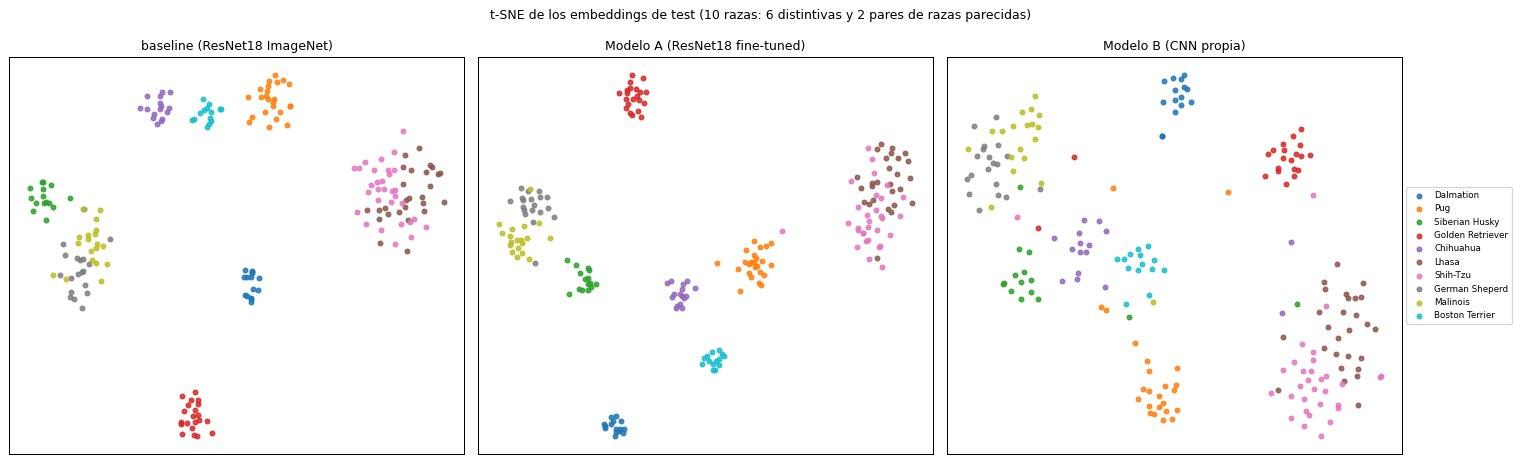

In [29]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

VIS_BREEDS = ["Dalmation", "Pug", "Siberian Husky", "Golden Retriever", "Chihuahua",
              "Lhasa", "Shih-Tzu", "German Sheperd", "Malinois", "Boston Terrier"]
mask = SETS["test"].breed.isin(VIS_BREEDS).to_numpy()
labels_vis = SETS["test"].breed[mask].to_numpy()
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
colors = dict(zip(VIS_BREEDS, plt.cm.tab10.colors))
for ax, (m, E) in zip(axes, EMB_MODELS.items()):
    X = E["test"][mask]
    Z = TSNE(n_components=2, perplexity=25, init=PCA(n_components=2, random_state=SEED).fit_transform(X),
             random_state=SEED).fit_transform(X)
    for b in VIS_BREEDS:
        sel = labels_vis == b
        ax.scatter(Z[sel, 0], Z[sel, 1], s=14, color=colors[b], label=b, alpha=0.85)
    ax.set_title(NAMES[m], fontsize=10)
    ax.set_xticks([])
    ax.set_yticks([])
axes[-1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1, 0.5))
fig.suptitle("t-SNE de los embeddings de test (10 razas: 6 distintivas y 2 pares de razas parecidas)", fontsize=10)
plt.tight_layout()
plt.show()

**Interpretación.**

- **En `test`, el Modelo A da los mejores embeddings para la búsqueda:** NDCG@10 de **0,888**
  contra 0,817 del baseline (+7 puntos). El *fine-tuning* acerca entre sí las imágenes de la misma
  raza, que es justo lo que mide el NDCG. En el t-SNE se ve: los grupos del Modelo A son más
  compactos y separados. Los pares difíciles (Lhasa / Shih-Tzu, German Sheperd / Malinois) siguen
  mezclados en los tres modelos.
- **En el conjunto independiente el baseline sigue siendo el mejor** (0,595 contra 0,572; accuracy
  0,69 contra 0,64): la misma pérdida de robustez de la sección 8. Con 100 consultas, 2 puntos de
  NDCG están dentro del ruido.
- **La CNN propia queda por debajo en todo** (0,730 en test, 0,248 en el independiente). Sus
  grupos del t-SNE están más dispersos y con intrusos de otras razas.
- **Elección de `EMBEDDING_MODEL`: se mantiene `baseline`.** En el escenario de uso real (fotos
  como las del conjunto independiente) rinde igual o mejor que el Modelo A, no depende de un
  checkpoint entrenado y su umbral ya está calibrado (sección 5.7). Si la app trabajara con
  recortes como los del dataset, convendría `resnet18_finetuned`, reindexando y recalibrando el
  umbral.

## 10. Análisis de errores

Errores del Modelo A en `test` y en el conjunto independiente. Para una raza X, un **falso
negativo** es una imagen de X clasificada como otra raza, y un **falso positivo** es una imagen
de otra raza clasificada como X. Se muestran los errores con mayor confianza (los más "seguros"
del modelo), que son los más informativos: un error con probabilidad 0,3 es una duda, uno con
0,9 indica que algo de la imagen engaña al modelo.

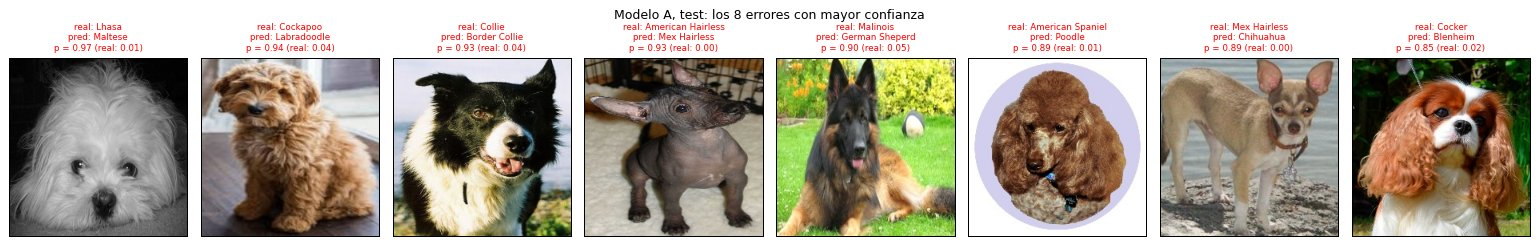

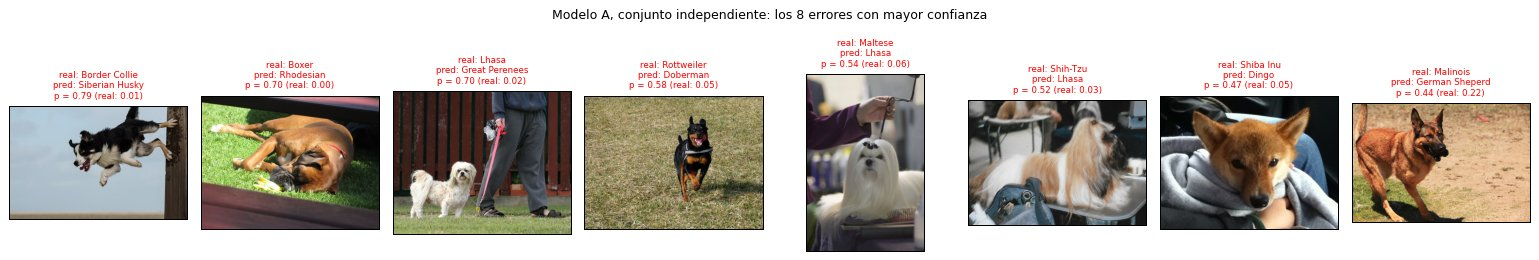

In [30]:
def show_errors(m, split, n=8, title=""):
    y, p = EVAL[m][split]
    classes = EVAL[m]["classes"]
    paths = (load_eval(m)[3] if split == "test" else IND.abs_path.tolist())
    pred = p.argmax(1)
    wrong = np.where(pred != y)[0]
    wrong = wrong[np.argsort(-p[wrong, pred[wrong]])][:n]
    fig, axes = plt.subplots(1, len(wrong), figsize=(2.15 * len(wrong), 2.9))
    for ax, i in zip(np.atleast_1d(axes), wrong):
        ax.imshow(bgr_to_rgb(read_bgr(paths[i])))
        ax.set_title(f"real: {classes[y[i]]}\npred: {classes[pred[i]]}\np = {p[i, pred[i]]:.2f} "
                     f"(real: {p[i, y[i]]:.2f})", fontsize=7, color="red")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


show_errors("resnet18_finetuned", "test", title="Modelo A, test: los 8 errores con mayor confianza")
show_errors("resnet18_finetuned", "independiente", title="Modelo A, conjunto independiente: los 8 errores con mayor confianza")

Razas con peor F1 del Modelo A en test: ['Lhasa', 'Cockapoo', 'Shih-Tzu']


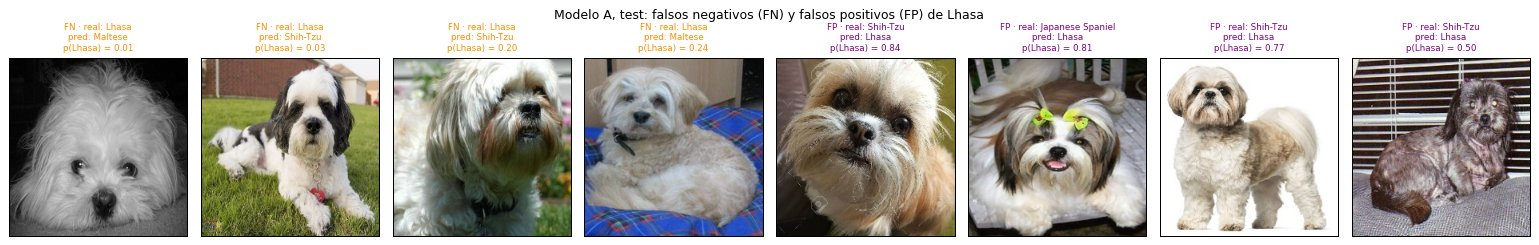

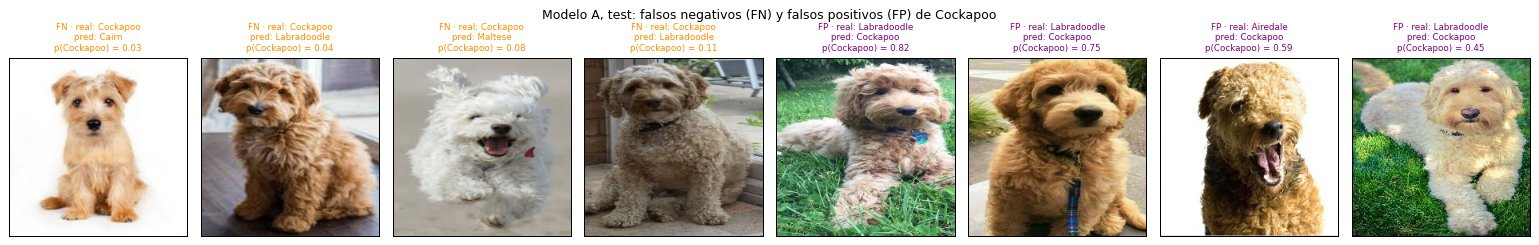

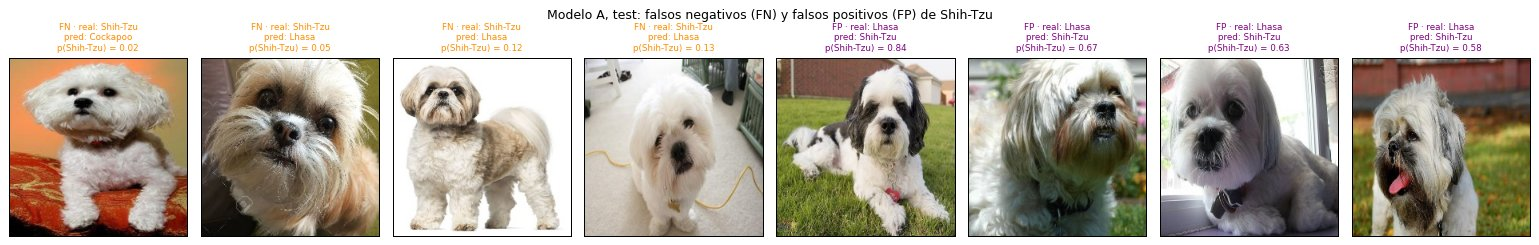

In [31]:
def fp_fn_examples(m, breed, split="test", n=4):
    y, p = EVAL[m][split]
    classes = EVAL[m]["classes"]
    paths = (load_eval(m)[3] if split == "test" else IND.abs_path.tolist())
    c = classes.index(breed)
    pred = p.argmax(1)
    fn = np.where((y == c) & (pred != c))[0]
    fp = np.where((y != c) & (pred == c))[0]
    fn, fp = fn[np.argsort(p[fn, c])][:n], fp[np.argsort(-p[fp, c])][:n]
    items = [("FN", i) for i in fn] + [("FP", i) for i in fp]
    if not items:
        return
    fig, axes = plt.subplots(1, len(items), figsize=(2.15 * len(items), 2.9))
    for ax, (kind, i) in zip(np.atleast_1d(axes), items):
        ax.imshow(bgr_to_rgb(read_bgr(paths[i])))
        ax.set_title(f"{kind} · real: {classes[y[i]]}\npred: {classes[pred[i]]}\n"
                     f"p({breed[:12]}) = {p[i, c]:.2f}", fontsize=7, color="darkorange" if kind == "FN" else "purple")
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(f"Modelo A, {split}: falsos negativos (FN) y falsos positivos (FP) de {breed}", fontsize=10)
    plt.tight_layout()
    plt.show()


worst_breeds = per_class_a.index[:3].tolist()
print("Razas con peor F1 del Modelo A en test:", worst_breeds)
for b in worst_breeds:
    fp_fn_examples("resnet18_finetuned", b)

**Interpretación de los errores.**

- **Etiquetas erróneas en el dataset:** varios de los errores "más seguros" del Modelo A en test
  son en realidad aciertos. La imagen etiquetada "Collie" es un Border Collie (blanco y negro, pelo
  corto en la cara), la "American Spaniel" es un dibujo de un Poodle y la "Cocker" es un Cavalier
  King Charles de color Blenheim (que es justo la raza que predice el modelo). Estos casos bajan la
  accuracy medida sin que el modelo esté equivocado.
- **Razas que ni las etiquetas separan:** en los falsos negativos y positivos de Lhasa, los
  perros etiquetados Lhasa y Shih-Tzu tienen el mismo pelaje, color y cara. El modelo duda con
  razón (probabilidades de 0,2 a 0,8). Algo parecido pasa con Cockapoo y Labradoodle, dos cruzas
  con caniche del mismo color.
- **Imagen atípica:** el Lhasa en blanco y negro (escala de grises) pierde la información de color
  y se va a Maltese con 0,97.
- **En el conjunto independiente:** perros en movimiento o en poses poco comunes (el Border
  Collie saltando, el Boxer acostado), perros chicos dentro de una escena (el Rottweiler en un
  campo) y fotos con personas (el Lhasa con una correa). En todos, el perro ocupa una parte chica
  de la imagen o aparece en una pose que no está en el dataset.
- **Qué haría falta:** limpiar las etiquetas de las clases conflictivas, más fotos con contexto en
  train (o augmentation de encuadre más agresiva) y, para fotos completas, recortar con YOLO antes
  de clasificar (sección 14).

## 11. Costo computacional

Parámetros, tamaño del checkpoint, dimensión del embedding y tiempo de inferencia por imagen en
**CPU** (una imagen por vez, como en la app: incluye el preprocesamiento; mediana de 50 imágenes
después de 5 de calentamiento). El baseline es el mismo ResNet18 sin la cabeza.

In [32]:
import copy

cpu_threads = torch.get_num_threads()
sample_imgs = [read_bgr(p) for p in SETS["test"].abs_path[:55]]


def cpu_time_ms(fn):
    times = []
    for i, img in enumerate(sample_imgs):
        t0 = time.perf_counter()
        fn(img)
        if i >= 5:
            times.append((time.perf_counter() - t0) * 1000)
    return float(np.median(times))


from lib.preprocessing import preprocess_bgr

cost_rows = []
for m in ["baseline", *MODELS]:
    if m == "baseline":
        net = similarity._get_backbone()
        ckpt_mb = np.nan
    else:
        classifier.set_active_model(m)
        net = classifier.load_model()
        ckpt_mb = classifier.active_checkpoint.stat().st_size / 2**20
    net_cpu = copy.deepcopy(net).cpu().eval()
    embed = net_cpu if m == "baseline" else net_cpu.embed

    def run(img, embed=embed):
        with torch.no_grad():
            return embed(torch.from_numpy(preprocess_bgr(img, settings.image_size)).unsqueeze(0))

    cost_rows.append({"modelo": NAMES[m], "parámetros": sum(p.numel() for p in net_cpu.parameters()),
                      "checkpoint (MB)": ckpt_mb, "dim. embedding": int(run(sample_imgs[0]).shape[1]),
                      "CPU ms/imagen": cpu_time_ms(run)})
cost = pd.DataFrame(cost_rows).set_index("modelo")
display(cost.round(1))
print(f"CPU: {torch.get_num_threads()} hilos de PyTorch")

,parámetros,checkpoint (MB),dim. embedding,CPU ms/imagen
modelo,,,,
baseline (ResNet18 ImageNet),11176512,NaN,512,18.4
Modelo A (ResNet18 fine-tuned),11212422,42.9,512,19.8
Modelo B (CNN propia),5180006,19.8,512,10.7


CPU: 6 hilos de PyTorch


**Interpretación.**

- **El Modelo B es el doble de liviano y rápido:** 5,2 M de parámetros, 19,8 MB y ~10 ms por imagen
  en CPU, contra 11,2 M, 42,9 MB y ~20 ms del Modelo A. Es el efecto del stem que reduce a 56 × 56
  antes de los bloques (sección 7).
- **Los dos son rápidos para la app:** unos 20 ms o menos por imagen en CPU, frente a los ~50 ms de
  YOLOv8n por imagen. En la Etapa 3, una foto con 3 perros cuesta ~50 ms de detección + 3 × 20 ms
  de clasificación: el clasificador no es el cuello de botella.
- **Los tres embeddings tienen la misma dimensión (512)**, así que la base vectorial y la búsqueda
  cuestan lo mismo con cualquiera de ellos.

## 12. Comparación y elección final

In [33]:
final = pd.DataFrame({
    NAMES[m]: {
        **{f"{k} (test)": metrics_table.loc[(MODELS[m], "test"), k] for k in ("accuracy", "precision", "recall", "specificity", "f1")},
        "accuracy (independiente)": metrics_table.loc[(MODELS[m], "independiente"), "accuracy"],
        "f1 (independiente)": metrics_table.loc[(MODELS[m], "independiente"), "f1"],
    } if m != "baseline" else {}
    for m in NAMES
}).T
ret = ret_table.pivot(index="embeddings", columns="conjunto")
final["NDCG@10 (test)"] = ret[("NDCG@10", "test")]
final["NDCG@10 (independiente)"] = ret[("NDCG@10", "independiente")]
final["accuracy búsqueda (test)"] = ret[("accuracy", "test")]
final = final.join(cost)
final_t = final.reindex(list(NAMES.values())).T


def fmt_cell(row, v):
    if pd.isna(v):
        return "—"
    if row in ("parámetros", "dim. embedding"):
        return f"{v:,.0f}"
    if row in ("checkpoint (MB)", "CPU ms/imagen"):
        return f"{v:.1f}"
    return f"{v:.3f}"


display(pd.DataFrame({c: [fmt_cell(r, final_t.loc[r, c]) for r in final_t.index] for c in final_t.columns},
                     index=final_t.index))
print("— : no aplica (el baseline no clasifica; sus pesos son los de torchvision, no un checkpoint propio)")

,baseline (ResNet18 ImageNet),Modelo A (ResNet18 fine-tuned),Modelo B (CNN propia)
accuracy (test),—,0.906,0.762
precision (test),—,0.910,0.769
recall (test),—,0.909,0.761
specificity (test),—,0.999,0.997
f1 (test),—,0.908,0.760
accuracy (independiente),—,0.570,0.270
f1 (independiente),—,0.636,0.320
NDCG@10 (test),0.817,0.888,0.730
NDCG@10 (independiente),0.595,0.572,0.248
accuracy búsqueda (test),0.889,0.907,0.760


— : no aplica (el baseline no clasifica; sus pesos son los de torchvision, no un checkpoint propio)


### Conclusión

**Configuración de la app:**

| Uso | Elección | Por qué |
|---|---|---|
| Clasificación (Etapas 2 y 3) | **Modelo A** (`resnet18_finetuned`) | El mejor en todas las métricas: 0,906 de accuracy en test y 0,57 en el independiente (más del doble que el Modelo B); ~20 ms por imagen en CPU alcanza de sobra |
| Embeddings de la búsqueda (`EMBEDDING_MODEL`) | **`baseline`** | Igual o mejor que el Modelo A en fotos reales (conjunto independiente), sin depender de un checkpoint; umbral ya calibrado (0,77) |
| Detector (Etapa 3) | YOLOv8n, `YOLO_CONF_THRESHOLD = 0.25` | Sección 14 |

**Fine-tuning vs. CNN propia.** El preentrenamiento es la diferencia: el Modelo A parte de
representaciones aprendidas con 1,2 M de imágenes y solo las ajusta; la CNN propia tiene que
aprenderlas con 6000. Con estos datos, la CNN rinde 14 puntos menos en test y 30 menos en el
conjunto independiente, aun siendo el doble de rápida. Solo convendría con muchos más datos o si
el costo de inferencia fuera crítico (por ejemplo, en un dispositivo móvil).

**Búsqueda por similitud vs. clasificación supervisada.**
- *Búsqueda:* no necesita entrenamiento, agregar una raza es indexar sus fotos (sin reentrenar),
  devuelve ejemplos visibles que explican la predicción y permite un rechazo natural (`unknown`)
  por similitud. Como desventajas, depende de la galería (tiene que estar indexada y en el mismo
  espacio de embeddings), el costo crece con el tamaño de la galería y separa peor las razas
  parecidas.
- *Clasificación:* aprende los rasgos que separan las 70 razas (mejor en test: 0,906 contra 0,889),
  es más rápida (una pasada, sin consultar la base) y no necesita la galería en producción. Como
  desventajas, agregar una raza requiere reentrenar, siempre elige una de las 70 (no tiene un
  rechazo natural: un Jack Russell o un zorro reciben igual alguna raza) y, como se vio, se
  especializa en el dominio de entrenamiento.
- *Cuándo conviene cada una:* clasificación cuando las clases son fijas y las imágenes se parecen a
  las de entrenamiento (como los recortes de YOLO); búsqueda cuando las clases cambian, cuando se
  quiere mostrar ejemplos similares o cuando las consultas vienen de otro dominio.

**Trade-offs:** el Modelo A cuesta el doble de memoria y tiempo que el Modelo B, pero da 14 puntos
más de accuracy; para esta app (inferencia de una imagen por vez, en CPU, unos 20 ms) la precisión
pesa más que esa diferencia de costo.

## 13. Checkpoints

Los checkpoints quedan en `models/` (fuera del control de versiones) y se publican en un link de
solo lectura (ver el README). Para usarlos en la app hay que copiarlos a `models/` del repositorio.

In [34]:
for p in sorted(settings.model_path.rglob("*.pth")):
    print(f"{p.as_posix()}  {p.stat().st_size / 2**20:.1f} MB")

models/cnn_custom.pth  19.8 MB
models/experiments/cnn_e1.pth  19.1 MB
models/experiments/cnn_e2.pth  19.1 MB
models/resnet18_feature_extraction.pth  42.9 MB
models/resnet18_finetuned.pth  42.9 MB
models/torch/hub/checkpoints/resnet18-f37072fd.pth  44.7 MB


## 14. Etapa 3 — Validación de la detección y clasificación

`detect_dogs` (YOLOv8n preentrenado en COCO, clase `dog` = 16, `YOLO_CONF_THRESHOLD` del `.env`)
y `classify_detected_dog` (Modelo A sobre el recorte) se validan con las escenas del conjunto
independiente: fotos de un perro (`breed`, 100), escenas con varios perros (`multi_dog`, 13) y
escenas sin perros con gatos y zorros (`no_dog`, 20), usando el pipeline completo de la app
(`DetectionService.predict`). Enunciado 6.3: un perro, varios perros, escenas complejas y sin perros.

In [35]:
from lib.bootstrap import build_detection
from lib.visualization.draw import draw_detections

classifier.set_active_model("resnet18_finetuned")
detection = build_detection(settings, classifier)
SCENES = SETS["independent"]
scene_imgs = {p: read_bgr(p) for p in SCENES.abs_path}

# Una pasada con umbral muy bajo; después se filtra por cada umbral candidato.
detection.conf_threshold = 0.05
t0 = time.time()
RAW_DETS = {p: detection.detect_dogs(img) for p, img in scene_imgs.items()}
print(f"YOLOv8n: {(time.time() - t0) / len(scene_imgs) * 1000:.0f} ms por imagen en {DEVICE}")
detection.conf_threshold = settings.yolo_conf_threshold

rows = []
for thr in (0.10, 0.25, 0.40, 0.50):
    n = {p: sum(c >= thr for _, c in dets) for p, dets in RAW_DETS.items()}
    g = SCENES.set_index("abs_path").group
    rows.append({
        "YOLO_CONF_THRESHOLD": thr,
        "1 perro: con detección": np.mean([n[p] >= 1 for p in g.index[g == "breed"]]),
        "1 perro: con >1 caja": np.mean([n[p] > 1 for p in g.index[g == "breed"]]),
        "varios perros: escenas con ≥2 cajas": np.mean([n[p] >= 2 for p in g.index[g == "multi_dog"]]),
        "varios perros: cajas totales": sum(n[p] for p in g.index[g == "multi_dog"]),
        "sin perro: con falso positivo": np.mean([n[p] >= 1 for p in g.index[g == "no_dog"]]),
    })
display(pd.DataFrame(rows).set_index("YOLO_CONF_THRESHOLD").style.format(
    {c: "{:.0%}" for c in rows[0] if c not in ("YOLO_CONF_THRESHOLD", "varios perros: cajas totales")}).format_index("{:.2f}"))

INFO:lib.services.detection_service:Detector YOLO cargado: /mnt/c/Users/facuq/Desktop/5to Cuatrimestre/tuia-dog-recognition-app/models/yolov8n.pt


YOLOv8n: 38 ms por imagen en cuda


,1 perro: con detección,1 perro: con >1 caja,varios perros: escenas con ≥2 cajas,varios perros: cajas totales,sin perro: con falso positivo
YOLO_CONF_THRESHOLD,,,,,
0.10,91%,5%,77%,27,20%
0.25,91%,1%,69%,24,15%
0.40,86%,1%,62%,20,10%
0.50,83%,0%,54%,19,10%


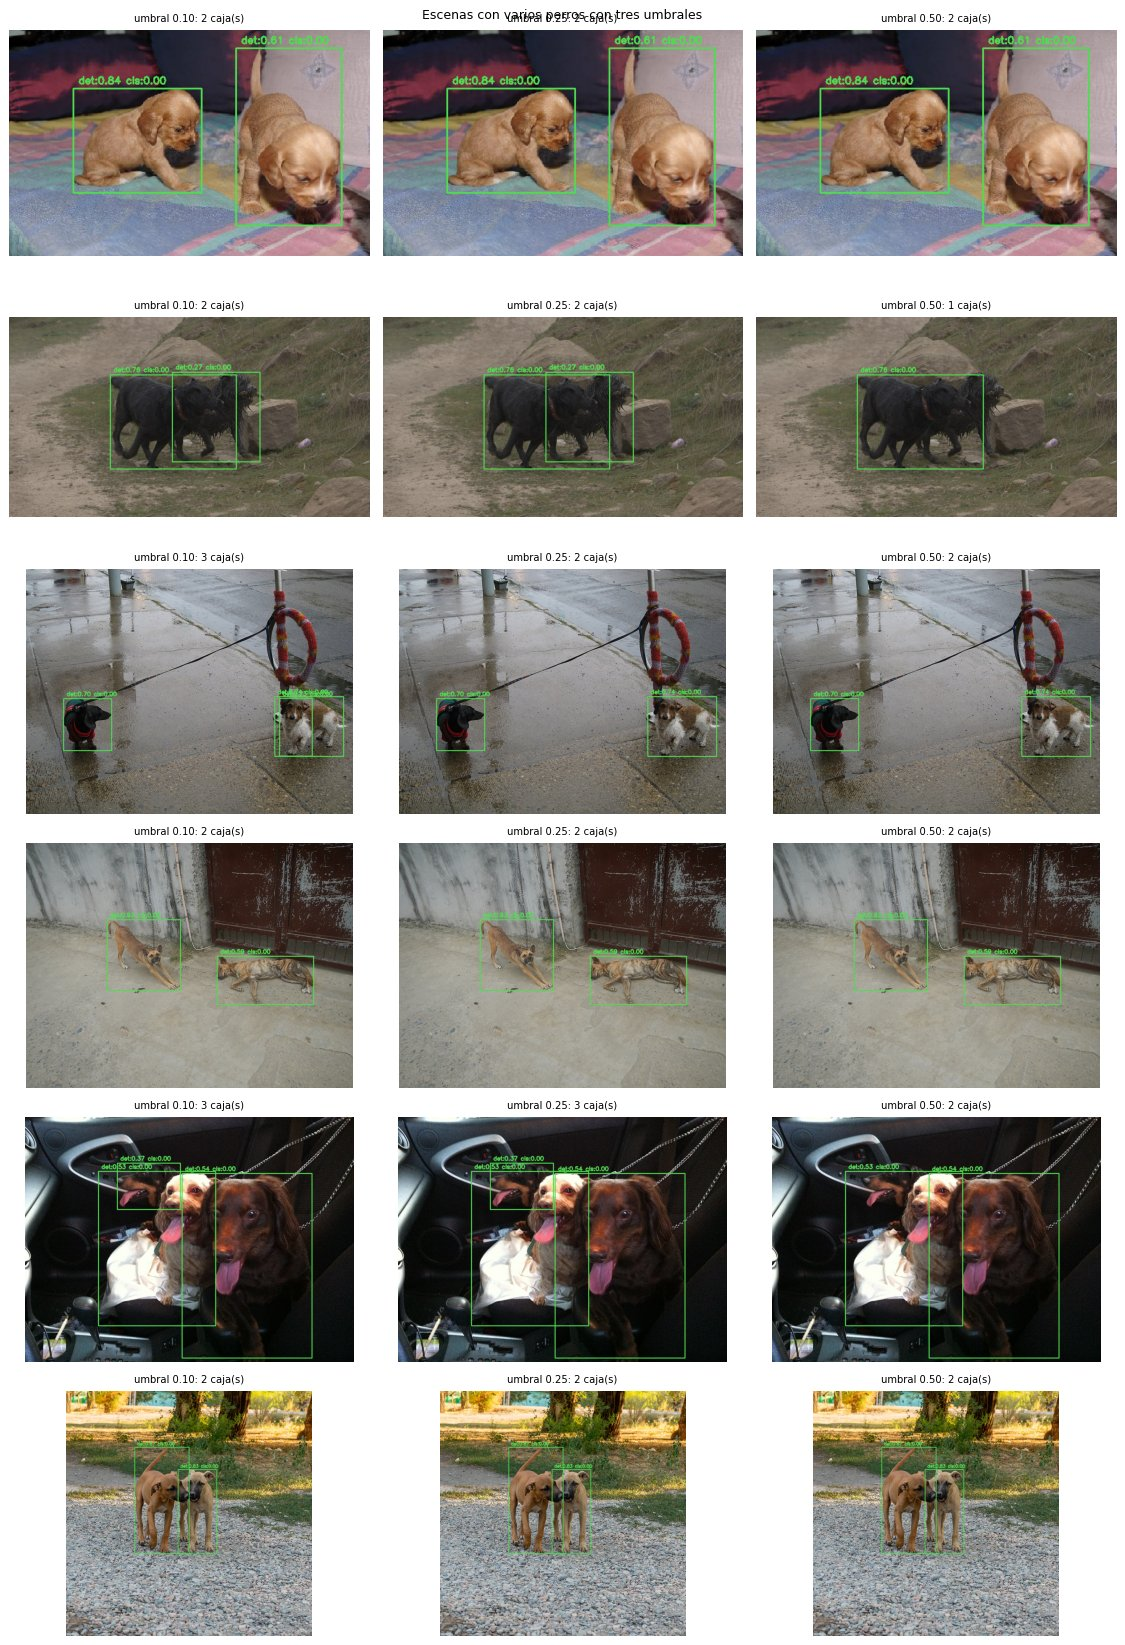

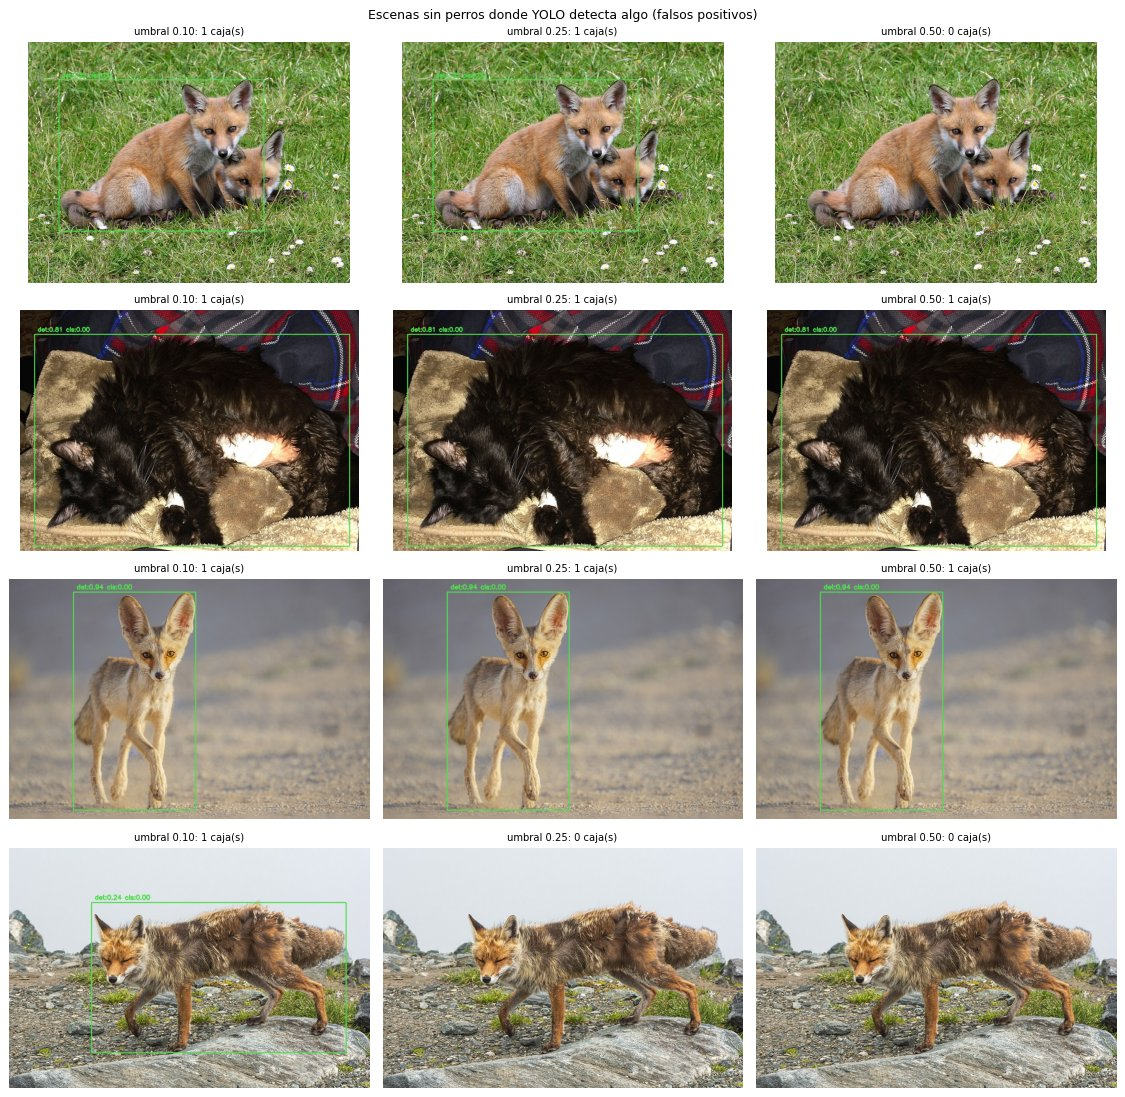

In [36]:
def show_scenes(paths, thresholds, title):
    fig, axes = plt.subplots(len(paths), len(thresholds), figsize=(4.2 * len(thresholds), 3.1 * len(paths)))
    axes = np.atleast_2d(axes)
    for r, p in enumerate(paths):
        img = scene_imgs[p]
        for c, thr in enumerate(thresholds):
            dets = [{"bbox": list(b), "det_score": s, "breed": "", "breed_score": 0.0}
                    for b, s in RAW_DETS[p] if s >= thr]
            axes[r, c].imshow(bgr_to_rgb(draw_detections(img, dets)))
            axes[r, c].set_title(f"umbral {thr:.2f}: {len(dets)} caja(s)", fontsize=8)
            axes[r, c].axis("off")
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


multi = SCENES.abs_path[SCENES.group == "multi_dog"].tolist()
fp_scenes = [p for p in SCENES.abs_path[SCENES.group == "no_dog"] if RAW_DETS[p] and max(s for _, s in RAW_DETS[p]) >= 0.10]
show_scenes(multi[:6], (0.10, 0.25, 0.50), "Escenas con varios perros con tres umbrales")
show_scenes(fp_scenes, (0.10, 0.25, 0.50), "Escenas sin perros donde YOLO detecta algo (falsos positivos)")

**Interpretación: `YOLO_CONF_THRESHOLD`.**

- **Fotos de un perro:** con 0,10 y 0,25 se detecta el perro en el 91% de las fotos; con 0,50 se
  pierde en el 17%. Las que no se detectan son perros en poses o encuadres poco comunes.
- **Varios perros:** bajar el umbral recupera perros parcialmente tapados (con 0,25, el 69% de las
  escenas tiene al menos 2 cajas; con 0,50, el 54%), pero con 0,10 empiezan a aparecer cajas
  duplicadas sobre el mismo perro (5% de las fotos de un solo perro tienen más de una caja).
- **Sin perros:** los falsos positivos son 2 zorros y un gato negro durmiendo. El zorro del desierto
  y el gato (confianza 0,94 y 0,81) se detectan con cualquier umbral razonable: para YOLO un zorro es
  un perro, y ningún umbral lo corrige sin perder perros reales. El otro zorro (0,35) desaparece
  con 0,40.
- **Se elige 0,25** (el valor por defecto): con el mismo recall en fotos de un perro que 0,10, sin
  cajas duplicadas y con un 15% de falsos positivos en escenas sin perros que son casi todos
  cánidos. Subirlo a 0,40 reduce los falsos positivos de 3 a 2 a costa de perder el 5% de los
  perros, y en esta app perder un perro es peor que clasificar un zorro.
- **Límites que se ven en el pipeline completo:** YOLOv8n (la versión más chica) no detecta los
  dálmatas detrás de una reja ni la camada de dálmatas superpuestos, y en el último ejemplo
  detecta solo uno de los dos perros. Además, el Jack Russell Terrier no es una de las 70 razas y
  el clasificador le asigna la más parecida (Chihuahua, Labrador), como se discutió en la conclusión.

**Pipeline completo** (`predict`: detección → recorte → clasificación) sobre escenas con varios
perros, con el umbral elegido y el Modelo A.

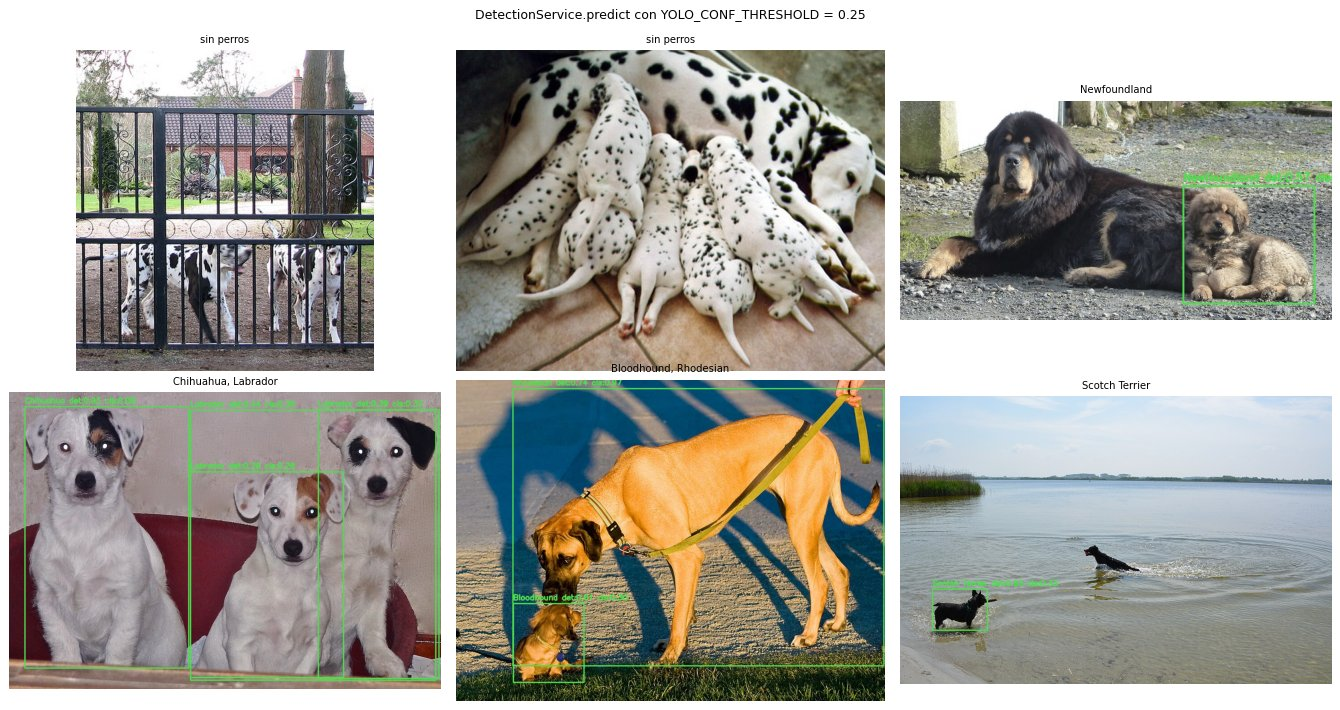

In [37]:
import tempfile

tmp_out = Path(tempfile.mkdtemp())
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, p in zip(axes.ravel(), multi[6:12]):
    res = json.loads(Path(detection.predict(p, tmp_out)).read_text(encoding="utf-8"))
    ax.imshow(bgr_to_rgb(draw_detections(scene_imgs[p], res["detections"])))
    ax.set_title(", ".join(res["detected_breeds"]) or "sin perros", fontsize=8)
    ax.axis("off")
fig.suptitle(f"DetectionService.predict con YOLO_CONF_THRESHOLD = {settings.yolo_conf_threshold}", fontsize=10)
plt.tight_layout()
plt.show()

**¿Clasificar el recorte de YOLO ayuda?** En las 100 fotos de un perro se compara el Modelo A
sobre la foto entera (pestaña de la Etapa 2) contra el Modelo A sobre el recorte de la detección
con mayor confianza (Etapa 3). Las fotos sin detección quedan como error en la columna del recorte.

In [38]:
rows = []
for r in IND.itertuples():
    img = scene_imgs[r.abs_path]
    whole, p_whole = detection.classify_detected_dog(img)
    dets = [d for d in RAW_DETS[r.abs_path] if d[1] >= settings.yolo_conf_threshold]
    if dets:
        x1, y1, x2, y2 = detection._clip_xyxy(*dets[0][0], *img.shape[:2])
        crop_breed, p_crop = detection.classify_detected_dog(img[y1:y2, x1:x2])
        frac = (x2 - x1) * (y2 - y1) / (img.shape[0] * img.shape[1])
    else:
        crop_breed, p_crop, frac = "sin detección", 0.0, np.nan
    rows.append({"raza": r.label, "foto entera": whole == r.label, "recorte YOLO": crop_breed == r.label,
                 "área del perro": frac})
crop_df = pd.DataFrame(rows)
crop_df["perro chico (<25% de la foto)"] = crop_df["área del perro"] < 0.25
summary = crop_df.groupby("perro chico (<25% de la foto)")[["foto entera", "recorte YOLO"]].agg(["mean", "size"])
print(f"Accuracy foto entera: {crop_df['foto entera'].mean():.2f} | recorte YOLO: {crop_df['recorte YOLO'].mean():.2f}")
display(summary.round(2))

Accuracy foto entera: 0.57 | recorte YOLO: 0.63


foto entera      recorte YOLO     
                                     mean size         mean size
perro chico (<25% de la foto)                                   
False                                0.60   86         0.65   86
True                                 0.36   14         0.50   14

**Interpretación.**

- **Clasificar el recorte de YOLO mejora la accuracy de 0,57 a 0,63** en las fotos del conjunto
  independiente, aun contando como error las 9 fotos donde YOLO no detecta el perro.
- **La mejora es mayor cuando el perro es chico:** si ocupa menos del 25% de la foto, pasa de 0,36 a
  0,50. Es lo esperable: el recorte acerca la foto al dominio de entrenamiento (perro centrado
  ocupando casi todo el cuadro), y el letterbox evita deformar los recortes alargados.
- Esto confirma que el pipeline de la Etapa 3 (detectar y después clasificar) es la forma correcta
  de usar el clasificador con fotos reales, y no solo una forma de manejar varios perros.